# **Traditional Image Processing for Filtering, 3D Reconstruction, and Image Stitching**
**Computer Vision · Midterm Project**
Student: **Tống Khánh Ly** – ID **23071036** – Class INS315501

Only classical (non-learning) methods are used: OpenCV, NumPy, Matplotlib, scikit-image (SSIM), Plotly (interactive 3D).

| Part | Content |
|---|---|
| A | Image filtering of my own photo: Mean, Gaussian (several σ), Median, Laplacian sharpening – 2 noise models, kernels 3/5/7 |
| B | 3D reconstruction from Middlebury (Venus, Teddy – course link): F + epipolar lines, BM vs SGBM, blockSize / numDisparities study, point cloud |
| C | Stitching 4 of my own photos: SIFT vs ORB vs AKAZE, RANSAC homography (4 thresholds), planar vs cylindrical, blending |

Every metric is implemented as its own function and every part compares ≥ 2 methods / parameter settings.

## Part A: Image Filtering and Enhancement
### Task
Synthesize noisy images from a clean image (Gaussian and salt-and-pepper noise) and compare four traditional
spatial filters across several kernel sizes.

### Input image
My own photograph of the place where I live (iPhone 12, view from my apartment window in Hanoi):
`data/own_photos/part_a/IMG_3115.jpg`, converted to grey-scale and resized to 800 × 450.

### Filters used
| Filter | Definition | Settings |
|---|---|---|
| Mean (box) | $g(x,y)=\frac{1}{k^2}\sum_{(i,j)\in\Omega} f(x+i,y+j)$ | k = 3, 5, 7 |
| Gaussian | weights $G(i,j)=\frac{1}{2\pi\sigma^2}e^{-(i^2+j^2)/2\sigma^2}$ | (k, σ) = (3, 0.8), (5, 1.1), (7, 1.4), (5, 0.5), (5, 2.0) |
| Median | $g(x,y)=\mathrm{median}\{f(x+i,y+j)\}$ (non-linear) | k = 3, 5, 7 |
| Laplacian sharpening | $g=f-\alpha\nabla^2 f$, kernel $\begin{bmatrix}0&1&0\\1&-4&1\\0&1&0\end{bmatrix}$ | α = 0.5 alone / after denoising; α = 0.5, 1, 2 on a blurred image |

### Noise models
* Additive Gaussian noise, σ = 20 (sensor noise)
* Salt & pepper noise, 5 % of pixels (impulse noise)

### Evaluation metrics
| Metric | Meaning |
|---|---|
| **PSNR** = 10·log₁₀(255²/MSE), **MSE** | noise reduction (higher PSNR / lower MSE = better) |
| **SSIM** | structural similarity (luminance · contrast · structure) |
| **Execution time (ms)** | median of 7 runs |
| EPI – Edge Preservation Index | correlation of the Laplacian high-pass of clean and filtered image (1 = edges kept) |
| Edge-F1 | F1 score of Canny edges vs. the clean image (1-px tolerance) |

In [1]:
# Import libraries
import csv
import glob
import os
import re
import time
from contextlib import contextmanager

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from skimage.metrics import structural_similarity

%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.precision", 3)

DATA_DIR = "data"
RESULTS_DIR = "results"
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 4.13.0 | NumPy 2.4.4


In [2]:
# Helper functions (I/O, timing, figures, tables)
def out_dir(part: str) -> str:
    """Return (and create) results/<part>/."""
    path = os.path.join(RESULTS_DIR, part)
    os.makedirs(path, exist_ok=True)
    return path

def imread(path: str, flags=cv2.IMREAD_COLOR):
    img = cv2.imread(path, flags)
    if img is None:
        raise FileNotFoundError(f"Cannot read image: {path}")
    return img

def resize_max(img, max_side: int):
    """Downscale so that the longer side is <= max_side (keeps aspect ratio)."""
    h, w = img.shape[:2]
    s = max_side / max(h, w)
    if s >= 1:
        return img
    return cv2.resize(img, (int(round(w * s)), int(round(h * s))), interpolation=cv2.INTER_AREA)

def bgr2rgb(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

@contextmanager
def timer(store: dict, key: str):
    t0 = time.perf_counter()
    yield
    store[key] = (time.perf_counter() - t0) * 1000.0  # milliseconds


def save_fig(fig, path, dpi=130):
    """Save a figure to results/ and show it inline."""
    fig.tight_layout()
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.show()


def write_table(rows, path_no_ext, float_fmt="{:.4f}"):
    """Save a list of dicts as CSV + Markdown (for the report) and display it."""
    if not rows:
        return None
    df = pd.DataFrame(rows)
    df.to_csv(path_no_ext + ".csv", index=False)
    with open(path_no_ext + ".md", "w", encoding="utf-8") as f:
        try:
            f.write(df.to_markdown(index=False, floatfmt=".4g"))
        except ImportError:                      # 'tabulate' not installed
            f.write(df.to_string(index=False))
    display(df)
    return df

In [3]:
# Metric functions (Part A)
def mse(ref, img):
    """Mean Squared Error: (1/N) Σ (I_ref − I)²."""
    return float(np.mean((ref.astype(np.float64) - img.astype(np.float64)) ** 2))

def psnr(ref, img, peak=255.0):
    """Peak Signal-to-Noise Ratio: 10·log10(peak² / MSE) [dB]. Higher = less noise."""
    m = mse(ref, img)
    return float("inf") if m == 0 else float(10 * np.log10(peak ** 2 / m))

def ssim(ref, img):
    """Structural Similarity (Wang et al. 2004): luminance·contrast·structure, in [−1, 1]."""
    return float(structural_similarity(ref, img, data_range=255, channel_axis=-1 if ref.ndim == 3 else None))

def edge_preservation_index(ref, img):
    """EPI (Sattar et al. 1997): normalised correlation of the Laplacian high-pass of the clean
    and the filtered image. 1 = edges perfectly preserved, 0 = edges destroyed."""
    a = cv2.Laplacian(ref.astype(np.float64), cv2.CV_64F)
    b = cv2.Laplacian(img.astype(np.float64), cv2.CV_64F)
    a -= a.mean()
    b -= b.mean()
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum() + 1e-12))

def edge_f1(ref, img, low=50, high=150, tol=1):
    """F1 score between Canny edge maps of ref and img (a match may be off by `tol` pixels)."""
    e_ref = cv2.Canny(ref, low, high) > 0
    e_img = cv2.Canny(img, low, high) > 0
    k = np.ones((2 * tol + 1, 2 * tol + 1), np.uint8)
    ref_d = cv2.dilate(e_ref.astype(np.uint8), k) > 0
    img_d = cv2.dilate(e_img.astype(np.uint8), k) > 0
    precision = (e_img & ref_d).sum() / max(e_img.sum(), 1)
    recall = (e_ref & img_d).sum() / max(e_ref.sum(), 1)
    return float(2 * precision * recall / max(precision + recall, 1e-12))

def sharpness(img):
    """Variance of the Laplacian – a standard no-reference focus/sharpness measure."""
    return float(cv2.Laplacian(img, cv2.CV_64F).var())

def filter_report(ref, img):
    """All Part-A metrics in one dict."""
    return dict(PSNR=psnr(ref, img), SSIM=ssim(ref, img), MSE=mse(ref, img),
                EPI=edge_preservation_index(ref, img), EdgeF1=edge_f1(ref, img))

In [4]:
# Noise models and filters
RNG_SEED = 42
PART_A_IMAGE = os.path.join(DATA_DIR, "own_photos", "part_a", "IMG_3115.jpg")

def add_gaussian_noise(img, sigma=20.0, seed=RNG_SEED):
    rng = np.random.default_rng(seed)
    noisy = img.astype(np.float32) + rng.normal(0.0, sigma, img.shape)
    return np.clip(noisy, 0, 255).astype(np.uint8)

def add_salt_pepper(img, amount=0.05, seed=RNG_SEED):
    rng = np.random.default_rng(seed)
    noisy = img.copy()
    r = rng.random(img.shape[:2])
    noisy[r < amount / 2] = 0          # pepper
    noisy[r > 1 - amount / 2] = 255    # salt
    return noisy

def mean_filter(img, k):
    """Box filter: every output pixel is the average of a k x k window."""
    return cv2.blur(img, (k, k))

def gaussian_filter(img, k, sigma=0):
    """Weighted average with a 2-D Gaussian kernel G(x,y)=exp(-(x²+y²)/2σ²)/(2πσ²).
    sigma=0 lets OpenCV derive σ = 0.3*((k-1)*0.5 - 1) + 0.8 from k."""
    return cv2.GaussianBlur(img, (k, k), sigma)

def median_filter(img, k):
    """Non-linear: replaces each pixel with the median of its k x k neighbourhood."""
    return cv2.medianBlur(img, k)

def laplacian_sharpen(img, alpha=1.0, ksize=1):
    """g = f - α ∇²f with the 4-neighbour kernel [[0,1,0],[1,-4,1],[0,1,0]] (ksize=1).
    The kernel centre is negative, so subtracting the Laplacian boosts edges."""
    f = img.astype(np.float32)
    lap = cv2.Laplacian(f, cv2.CV_32F, ksize=ksize)
    return np.clip(f - alpha * lap, 0, 255).astype(np.uint8)

def evaluate(ref, img):
    """PSNR, SSIM, EPI, Edge-F1 (+MSE) – implemented in metrics.py."""
    return filter_report(ref, img)


KERNELS = (3, 5, 7)
GAUSS_SIGMAS = {3: 0.8, 5: 1.1, 7: 1.4}          # OpenCV's default σ for each kernel size
EXTRA_SIGMAS = (0.5, 2.0)                        # σ study at a fixed 5x5 kernel


def build_filter_bank():
    """(name, function) – kernel sizes 3/5/7 for every filter and several σ for the Gaussian."""
    bank = []
    for k in KERNELS:
        bank.append((f"Mean {k}x{k}", lambda x, k=k: mean_filter(x, k)))
    for k in KERNELS:
        s = GAUSS_SIGMAS[k]
        bank.append((f"Gaussian {k}x{k} σ={s}", lambda x, k=k, s=s: gaussian_filter(x, k, s)))
    for s in EXTRA_SIGMAS:
        bank.append((f"Gaussian 5x5 σ={s}", lambda x, s=s: gaussian_filter(x, 5, s)))
    for k in KERNELS:
        bank.append((f"Median {k}x{k}", lambda x, k=k: median_filter(x, k)))
    # Laplacian sharpening alone on a noisy image amplifies noise; the useful pipeline is
    # "denoise first, then sharpen". Both are reported so the difference is visible.
    bank.append(("Laplacian sharpen (raw)", lambda x: laplacian_sharpen(x, 0.5)))
    bank.append(("Gaussian 5x5 + Laplacian", lambda x: laplacian_sharpen(gaussian_filter(x, 5, 1.1), 0.5)))
    bank.append(("Median 3x3 + Laplacian", lambda x: laplacian_sharpen(median_filter(x, 3), 0.5)))
    return bank

def timed(fn, x, repeats=7):
    """Run fn(x) several times and return (result, median runtime in ms) – stable timings."""
    times = []
    for _ in range(repeats):
        t = {}
        with timer(t, "ms"):
            res = fn(x)
        times.append(t["ms"])
    return res, float(np.median(times))

In [5]:
# Visualisation functions (Part A)
def side_by_side(clean, noisy, outputs, title, path, crop=None):
    """Original | Noisy | each filter, optionally zoomed into `crop` = (y0, y1, x0, x1)."""
    panels = [("Original", clean), ("Noisy", noisy)] + outputs
    if crop is not None:
        y0, y1, x0, x1 = crop
        panels = [(n, im[y0:y1, x0:x1]) for n, im in panels]
    ref = panels[0][1]
    cols = 4
    rows = int(np.ceil(len(panels) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 3.6 * rows))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (name, im) in zip(axes.ravel(), panels):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        label = name if name == "Original" else f"{name}\nPSNR {psnr(ref, im):.2f} dB"
        ax.set_title(label, fontsize=10)
    fig.suptitle(title, fontsize=14, fontweight="bold")
    save_fig(fig, path)

def line_profile(clean, noisy, outputs, row, path, title):
    """Intensity profile along one image row: shows how each filter treats an edge."""
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(noisy[row], color="0.75", lw=0.8, label="Noisy")
    ax.plot(clean[row], color="black", lw=2, label="Original")
    for name, im in outputs:
        ax.plot(im[row], lw=1.2, label=name)
    ax.set_xlabel("x (pixel)")
    ax.set_ylabel("Intensity")
    ax.set_title(title)
    ax.legend(ncol=3, fontsize=8)
    save_fig(fig, path)

def bar_chart(rows, path):
    """PSNR, SSIM and runtime of every filter for both noise models."""
    noises = list(dict.fromkeys(r["Noise"] for r in rows))
    filters = [r["Filter"] for r in rows if r["Noise"] == noises[0]]
    fig, axes = plt.subplots(3, 1, figsize=(15, 13), sharex=True)
    x = np.arange(len(filters))
    w = 0.38
    for ax, metric, unit in zip(axes, ("PSNR", "SSIM", "Time_ms"), ("dB", "", "ms")):
        for i, noise in enumerate(noises):
            vals = [next(r[metric] for r in rows if r["Noise"] == noise and r["Filter"] == f) for f in filters]
            ax.bar(x + (i - 0.5) * w, vals, w, label=noise)
        ax.set_ylabel(f"{metric} {unit}".strip())
        ax.grid(axis="y", alpha=0.3)
        ax.legend()
    axes[-1].set_xticks(x)
    axes[-1].set_xticklabels(filters, rotation=40, ha="right", fontsize=9)
    fig.suptitle("PSNR, SSIM (higher is better) and runtime (lower is better) of every filter", fontweight="bold")
    save_fig(fig, path)

def kernel_size_plot(rows, path):
    """Parameter sensitivity: PSNR and EPI versus kernel size for the three smoothing filters."""
    noises = list(dict.fromkeys(r["Noise"] for r in rows))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, metric in zip(axes, ("PSNR", "EPI")):
        for noise, ls in zip(noises, ("-", "--")):
            for fam in ("Mean", "Gaussian", "Median"):
                vals = []
                for k in KERNELS:
                    name = f"Gaussian {k}x{k} σ={GAUSS_SIGMAS[k]}" if fam == "Gaussian" else f"{fam} {k}x{k}"
                    vals.append(next(r[metric] for r in rows if r["Noise"] == noise and r["Filter"] == name))
                ax.plot(KERNELS, vals, ls, marker="o", label=f"{fam} – {noise}")
        ax.set_xticks(KERNELS)
        ax.set_xlabel("kernel size k (k×k)")
        ax.set_ylabel(metric)
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    fig.suptitle("Kernel-size sensitivity: more smoothing removes more noise but erases edges", fontweight="bold")
    save_fig(fig, path)

def sharpening_demo(clean, out):
    """Laplacian as *enhancement*: recover detail of a slightly blurred (noise-free) image."""
    blurred = gaussian_filter(clean, 5, 1.5)
    results = [("Blurred input", blurred)]
    rows = []
    for alpha in (0.5, 1.0, 2.0):
        sharp = laplacian_sharpen(blurred, alpha)
        results.append((f"Sharpened α={alpha}", sharp))
    for name, im in results:
        m = evaluate(clean, im)
        m["Sharpness (var ∇²)"] = sharpness(im)
        rows.append({"Image": name, **m})
    rows.insert(0, {"Image": "Original", **evaluate(clean, clean),
                    "Sharpness (var ∇²)": sharpness(clean)})
    write_table(rows, os.path.join(out, "laplacian_sharpening_metrics"))

    fig, axes = plt.subplots(1, len(results) + 1, figsize=(4.2 * (len(results) + 1), 4))
    for ax, (name, im) in zip(axes, [("Original", clean)] + results):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(name)
        ax.axis("off")
    fig.suptitle("Laplacian sharpening as enhancement (g = f − α∇²f)", fontweight="bold")
    save_fig(fig, os.path.join(out, "A3_laplacian_sharpening.png"))

    # halo / ringing: profile across the strongest horizontal edge of the image
    gx = np.abs(cv2.Sobel(clean.astype(np.float32), cv2.CV_32F, 1, 0, ksize=3))
    y, x = np.unravel_index(np.argmax(cv2.blur(gx, (1, 9))), gx.shape)
    x0, x1 = max(x - 25, 0), min(x + 25, clean.shape[1])
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(range(x0, x1), clean[y, x0:x1], color="black", lw=2.5, label="Original")
    for name, im in results:
        ax.plot(range(x0, x1), im[y, x0:x1], lw=1.4, label=name)
    ax.set_xlabel("x (pixel)"); ax.set_ylabel("Intensity")
    ax.set_title(f"Row {y}: overshoot on both sides of the edge = halo / ringing (grows with α)")
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
    save_fig(fig, os.path.join(out, "A6_halo_profile.png"))

image size: (450, 800)


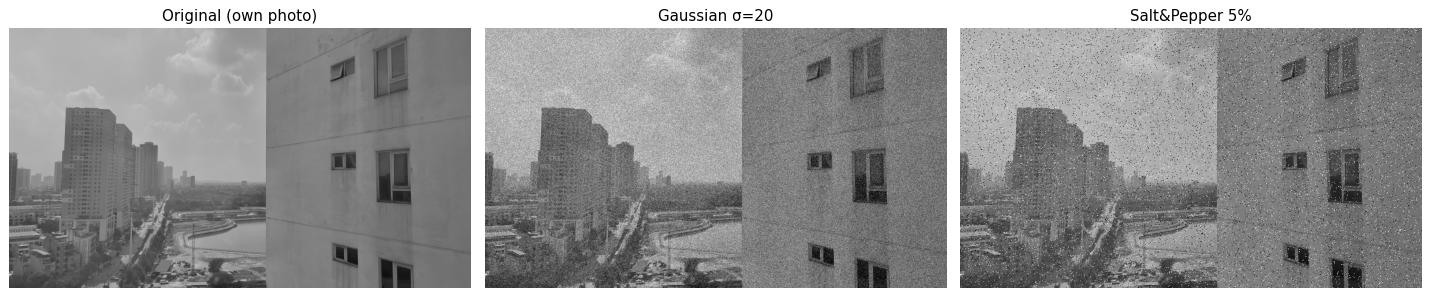

In [6]:
# Load my photo and add noise
out_a = out_dir(os.path.join("part_a", "own_photo"))
clean = resize_max(imread(PART_A_IMAGE, cv2.IMREAD_GRAYSCALE), 800)
noises = {"Gaussian σ=20": add_gaussian_noise(clean, 20), "Salt&Pepper 5%": add_salt_pepper(clean, 0.05)}
cv2.imwrite(os.path.join(out_a, "original_gray.png"), clean)
print("image size:", clean.shape)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, (name, im) in zip(axes, [("Original (own photo)", clean)] + list(noises.items())):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(name); ax.axis("off")
save_fig(fig, os.path.join(out_a, "A0_original_and_noisy.png"))

In [7]:
# Apply every filter to both noisy images: PSNR, SSIM, MSE, runtime (+ EPI, Edge-F1)
bank = build_filter_bank()
rows_a, outputs_a = [], {}
for noise_name, noisy in noises.items():
    rows_a.append({"Noise": noise_name, "Filter": "(no filter)", **evaluate(clean, noisy), "Time_ms": 0.0})
    outputs_a[noise_name] = []
    for name, fn in bank:
        res, ms = timed(fn, noisy)
        outputs_a[noise_name].append((name, res))
        rows_a.append({"Noise": noise_name, "Filter": name, **evaluate(clean, res), "Time_ms": ms})
df_a = write_table(rows_a, os.path.join(out_a, "filter_metrics"))

,Noise,Filter,PSNR,SSIM,MSE,EPI,EdgeF1,Time_ms
0,Gaussian σ=20,(no filter),22.110,0.251,400.056,0.172,0.299,0.000
1,Gaussian σ=20,Mean 3x3,29.921,0.653,66.222,0.053,0.727,0.074
2,Gaussian σ=20,Mean 5x5,30.618,0.777,56.406,-0.008,0.358,0.085
3,Gaussian σ=20,Mean 7x7,30.087,0.800,63.739,-0.006,0.072,0.249
4,Gaussian σ=20,Gaussian 3x3 σ=0.8,29.523,0.609,72.569,0.269,0.465,0.099
5,Gaussian σ=20,Gaussian 5x5 σ=1.1,31.083,0.739,50.668,0.261,0.673,0.121
6,Gaussian σ=20,Gaussian 7x7 σ=1.4,31.364,0.796,47.499,0.232,0.495,0.221
7,Gaussian σ=20,Gaussian 5x5 σ=0.5,25.836,0.399,169.607,0.215,0.307,0.124
8,Gaussian σ=20,Gaussian 5x5 σ=2.0,31.048,0.786,51.086,0.079,0.451,0.143
9,Gaussian σ=20,Median 3x3,28.747,0.575,86.781,0.106,0.494,0.075


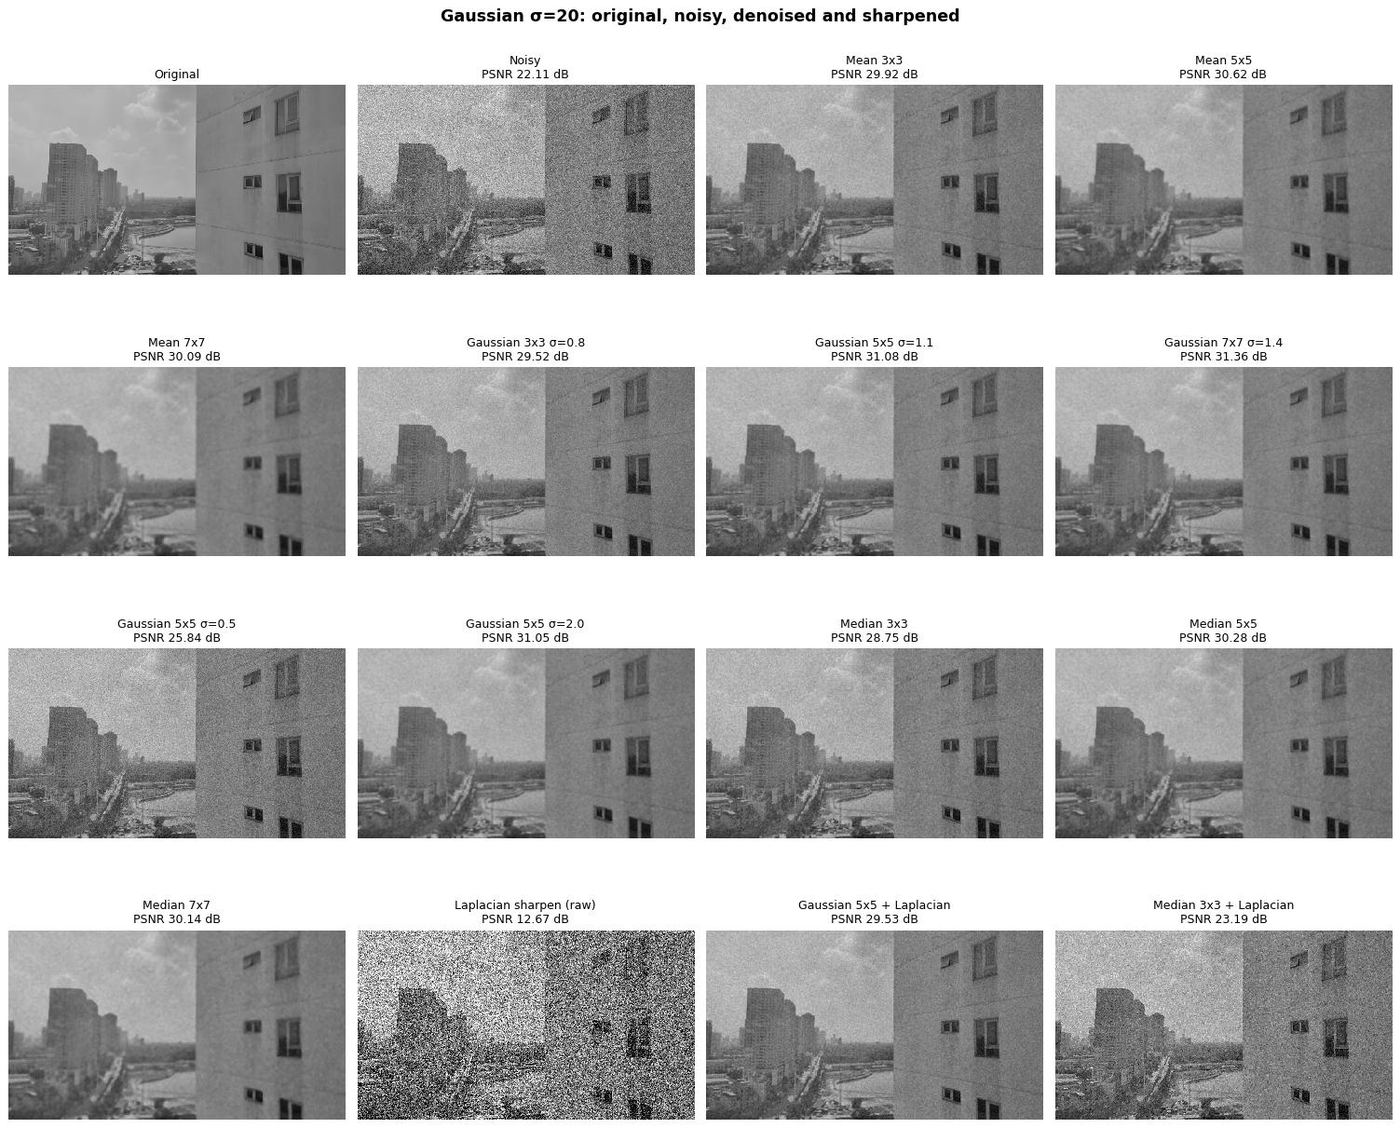

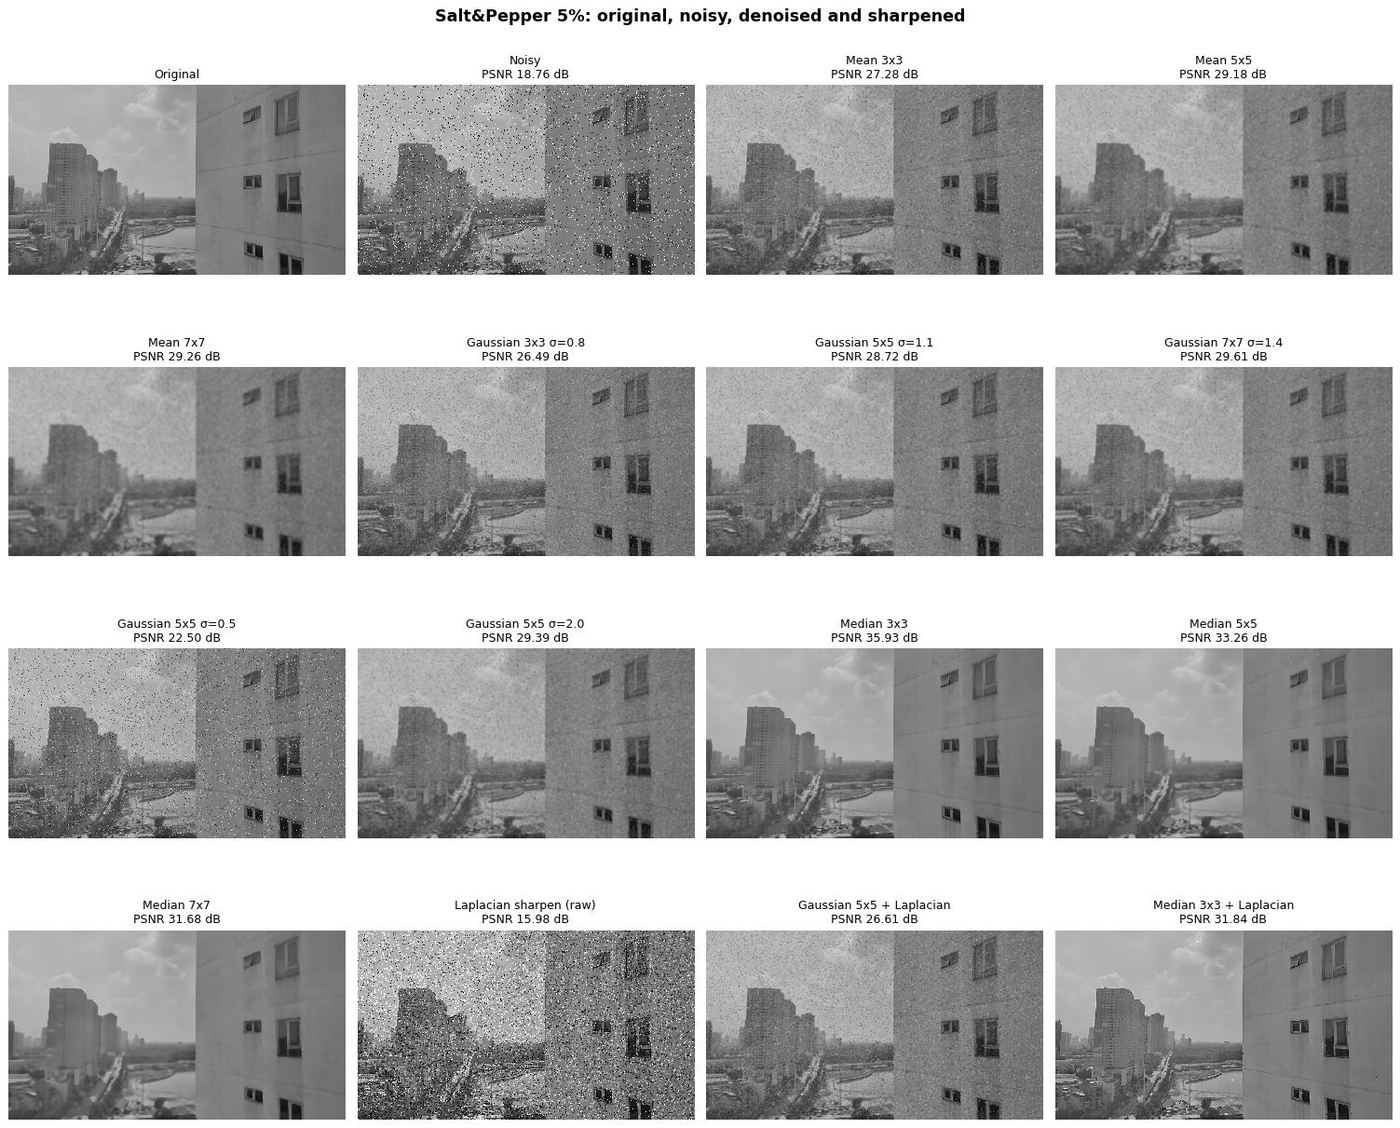

In [8]:
# Original, noisy, denoised and sharpened images side by side
for noise_name, noisy in noises.items():
    tag = "gaussian" if "Gaussian" in noise_name else "saltpepper"
    side_by_side(clean, noisy, outputs_a[noise_name], f"{noise_name}: original, noisy, denoised and sharpened",
                 os.path.join(out_a, f"A1_{tag}_side_by_side.png"))

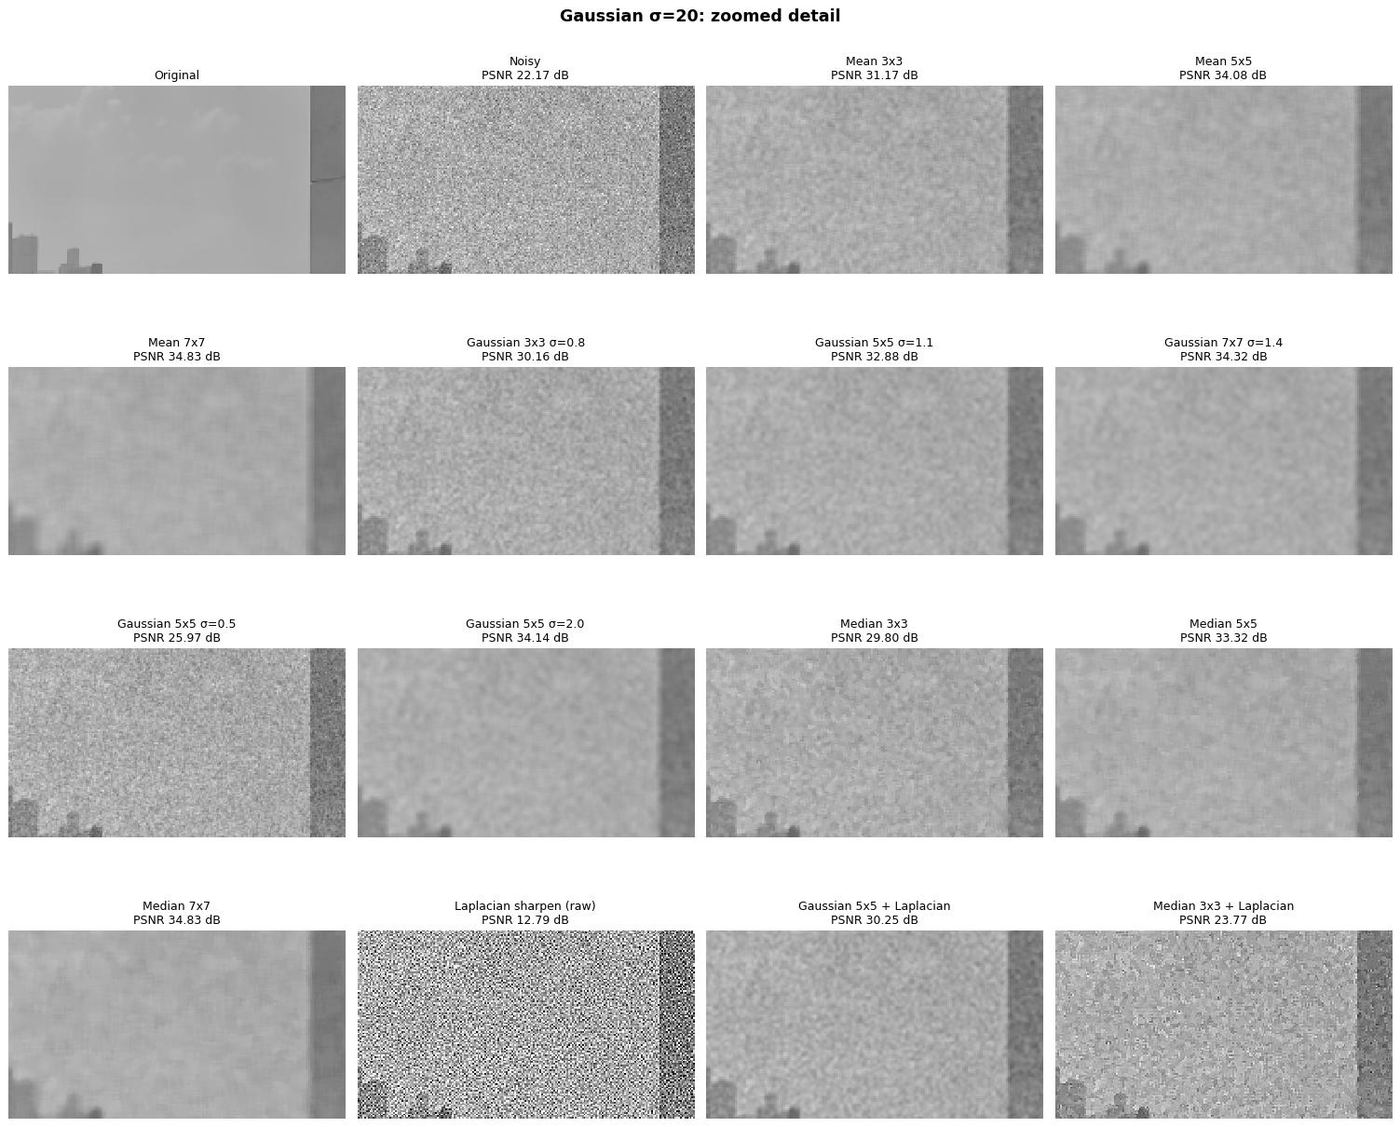

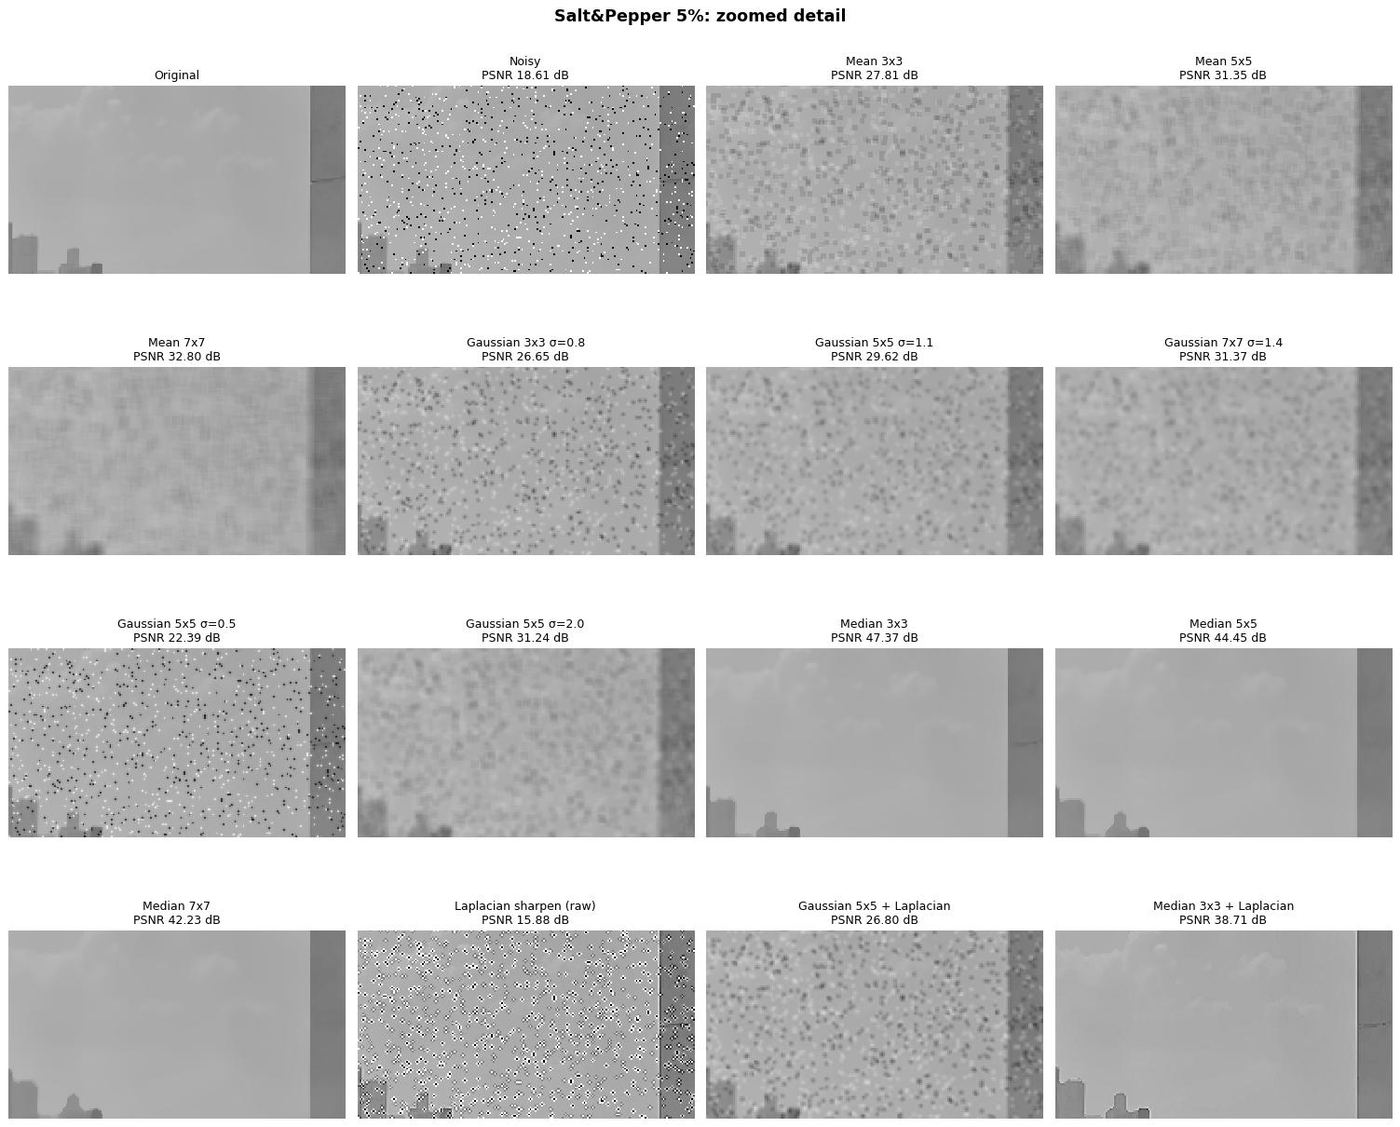

In [9]:
# Zoomed detail: edge preservation and over-smoothing are easier to judge on a crop
h, w = clean.shape
crop = (h // 3, h // 3 + h // 4, w // 3, w // 3 + w // 4)
for noise_name, noisy in noises.items():
    tag = "gaussian" if "Gaussian" in noise_name else "saltpepper"
    side_by_side(clean, noisy, outputs_a[noise_name], f"{noise_name}: zoomed detail",
                 os.path.join(out_a, f"A2_{tag}_zoom.png"), crop=crop)

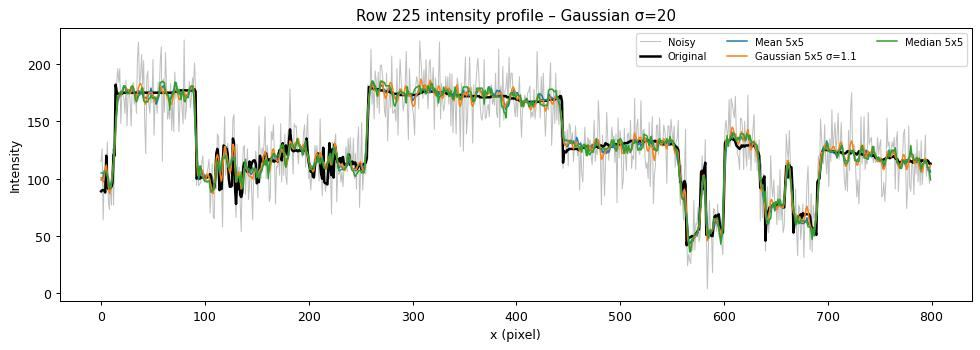

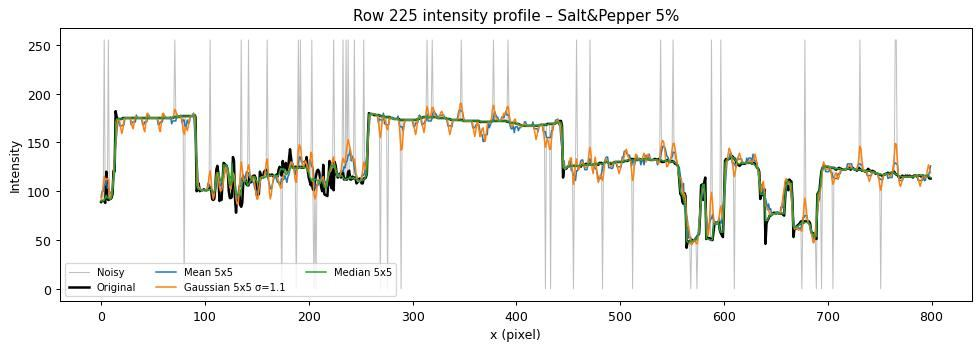

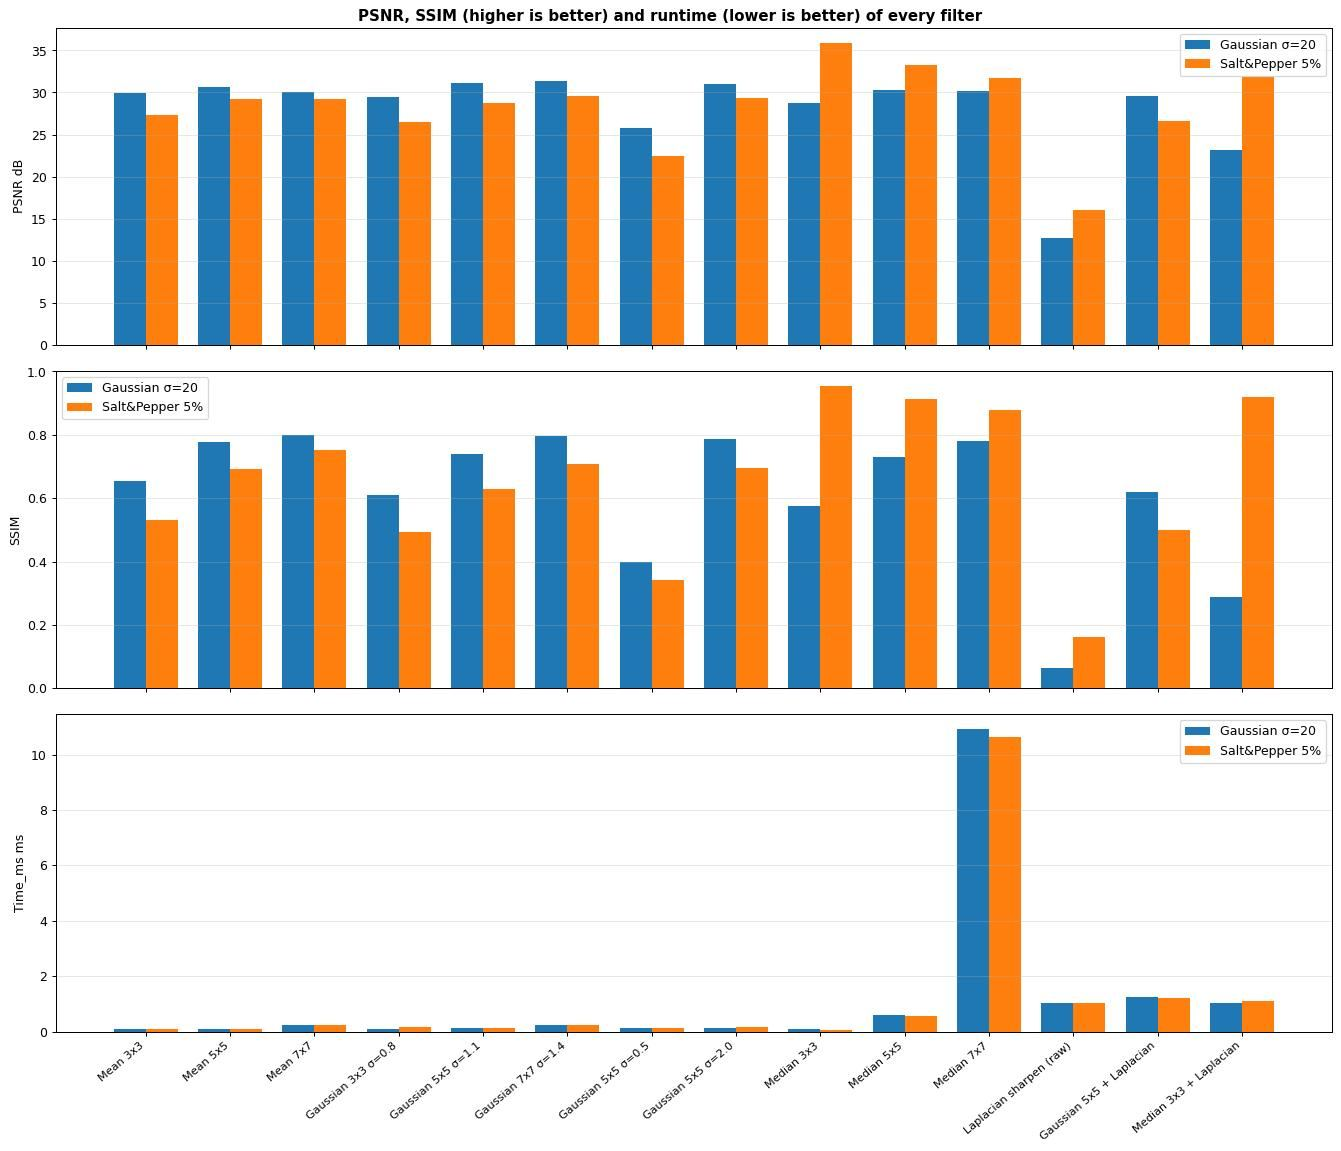

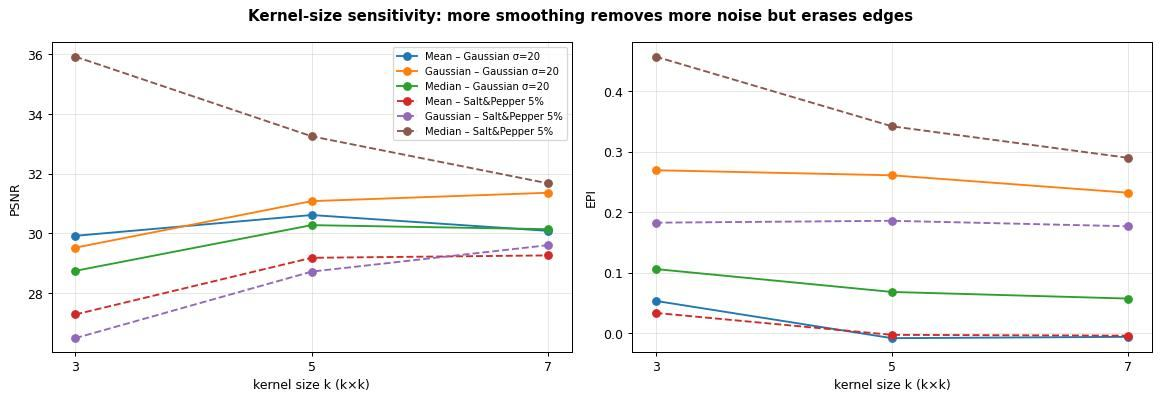

In [10]:
# Intensity profiles, metric bar charts and kernel-size sensitivity
for noise_name, noisy in noises.items():
    tag = "gaussian" if "Gaussian" in noise_name else "saltpepper"
    pick = [o for o in outputs_a[noise_name] if o[0] in ("Mean 5x5", "Gaussian 5x5 σ=1.1", "Median 5x5")]
    line_profile(clean, noisy, pick, h // 2, os.path.join(out_a, f"A4_{tag}_line_profile.png"),
                 f"Row {h // 2} intensity profile – {noise_name}")
bar_chart([r for r in rows_a if r["Filter"] != "(no filter)"], os.path.join(out_a, "A5_metrics_bar_chart.png"))
kernel_size_plot(rows_a, os.path.join(out_a, "A7_kernel_size_sensitivity.png"))

,Image,PSNR,SSIM,MSE,EPI,EdgeF1,Sharpness (var ∇²)
0,Original,inf,1.000,0.000,1.000,1.000,253.375
1,Blurred input,33.551,0.921,28.708,0.281,0.487,7.289
2,Sharpened α=0.5,34.356,0.930,23.849,0.197,0.634,33.389
3,Sharpened α=1.0,34.619,0.925,22.448,0.166,0.739,82.918
4,Sharpened α=2.0,33.252,0.881,30.751,0.141,0.853,259.898


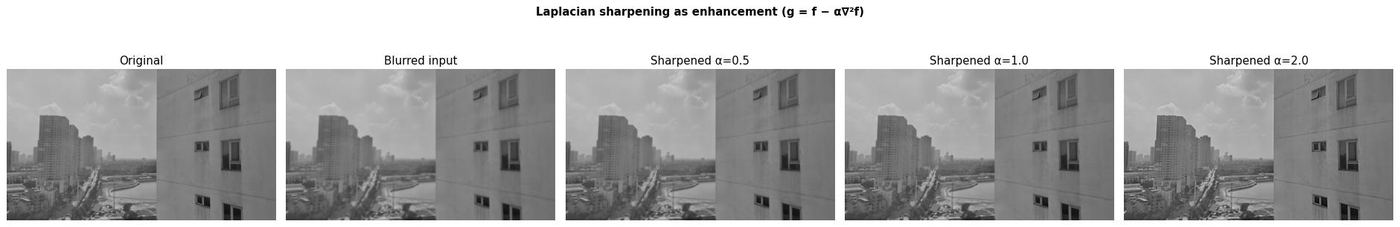

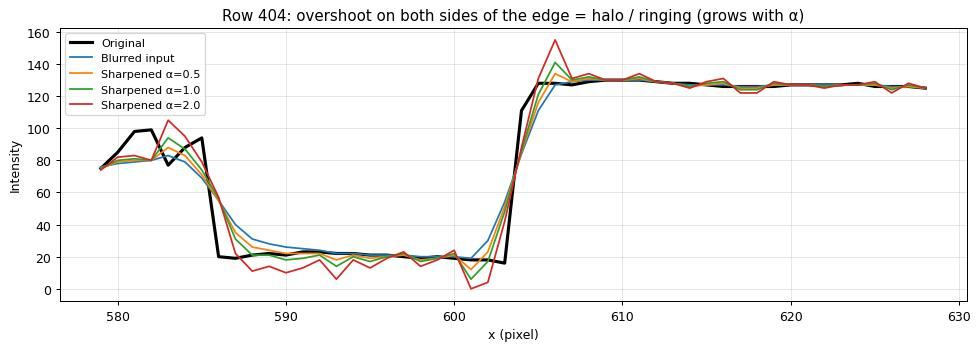

In [11]:
# Laplacian sharpening used as ENHANCEMENT on a blurred image + halo / ringing profile
sharpening_demo(clean, out_a)

### Part A – Comparative analysis
* **Gaussian noise**: larger smoothing kernels win on PSNR/SSIM because this hazy daytime scene contains mostly
  smooth regions (sky, walls): Gaussian 7×7 (σ = 1.4) reaches 31.4 dB / SSIM 0.80, Gaussian 5×5 (σ = 1.1) 31.1 dB.
  The mean filter blurs edges the most (Edge-F1 drops from 0.72 at 3×3 to 0.07 at 7×7); the Gaussian keeps more
  edges at the same noise reduction. A too small σ (0.5) barely smooths (25.8 dB).
* **Salt & pepper noise**: Median 3×3 wins clearly (35.9 dB, SSIM 0.95) – the median ignores outliers, whereas
  linear filters spread each impulse into a grey blotch (≤ 29.7 dB).
* **Kernel size**: bigger kernels remove more noise but erase window frames and thin lines (over-smoothing, see
  zoom, line profiles and the sensitivity plot). Median 7×7 is also > 100× slower than 3×3 (10.9 ms vs 0.07 ms).
* **Laplacian sharpening** applied directly amplifies noise (12.7–16.0 dB). On a blurred image it restores detail
  (33.6 → 34.6 dB at α = 1), but α = 2 overshoots: the profile shows bright/dark halos on both sides of edges and
  PSNR/SSIM drop although the sharpness measure keeps increasing.
* **Metric quirk**: EPI is low for every filter because the high-pass of the clean photo is dominated by fine
  texture and JPEG noise that any smoothing removes; PSNR, SSIM and Edge-F1 are more informative here.

## Part B: 3D Reconstruction
### Using stereo images
* Compute disparity map using **Block Matching (BM)** and **Semi-Global Block Matching (SGBM)**
* Reconstruct the **3D point cloud** from the disparity
* Estimate the **fundamental matrix** and draw **epipolar lines**

### Data – Middlebury set given by the lecturer (https://vision.middlebury.edu/flow/data/)
**Venus** (`other-color-twoframes.zip`, ground truth `other-gt-flow.zip`) and **Teddy** (`eval-color-twoframes.zip`)
are the two stereo scenes of that set:
* `frame10` = left view, `frame11` = right view; rows are aligned (vertical flow = 0), so the pair is rectified.
* The ground-truth flow of `frame10` gives the disparity directly: $d = x_L - x_R = -u$.
* The two frames are crops of the original rectified pair, shifted horizontally by $d_{offs}$ pixels
  (Venus 10 px, Teddy 26 px – measured by template matching against the original Middlebury stereo images),
  so disparities can be **negative** and depth follows Middlebury's convention $Z = fB/(d + d_{offs})$.
* Teddy's flow ground truth is hidden in the flow benchmark, so its public ground-truth disparity from the
  Middlebury stereo release (`disp2.png`, cropped to the same window) is used for evaluation.

### Brief explanation of the stereo algorithm
1. **Rectified pair** → corresponding points lie on the same row; disparity $d = x_L - x_R$.
2. **Search range** – estimated from sparse SIFT matches that satisfy the epipolar constraint (1st–99th percentile
   of $x_L - x_R$ ± 4 px), so the ground truth is used **only** for evaluation.
3. **BM**: for each pixel, compare a $k\times k$ block with blocks shifted by every $d$ in the range (Sum of
   Absolute Differences) and keep the best $d$ (*winner-takes-all*). Fast, but fails on textureless areas and
   occlusions.
4. **SGBM** (Hirschmüller 2008): minimises
   $E(D)=\sum_p C(p,D_p)+\sum_{q\in N_p}P_1[|D_p-D_q|=1]+\sum_{q\in N_p}P_2[|D_p-D_q|>1]$
   by aggregating matching costs along 8 directions → dense, piecewise-smooth disparity.
5. **Triangulation**: $Z=\frac{fB}{d+d_{offs}}$, $X=\frac{(u-c_x)Z}{f}$, $Y=\frac{(v-c_y)Z}{f}$
   (no calibration is published, so $f=0.8\,w$, $B=1$ → shape is correct, scale is relative).
6. **Fundamental matrix**: SIFT matches + ratio test, then $x_R^T F x_L=0$ solved by the 8-point algorithm,
   RANSAC and LMedS; epipolar line in the right image $l' = F x$.

### Metrics
**Valid disparity ratio %**, Left-Right consistency %, **Bad-1.0 %** (|d − d_gt| > 1 px, missing = bad),
Bad-1.0 on estimated pixels, **EPE** (mean |d − d_gt|), **RMSE**, runtime · for F: inliers, mean point-to-epipolar-line
distance, **mean Sampson error**, mean tilt of the lines (must be ≈ 0° for a rectified pair), rank-2 check.

In [12]:
# Parameters
SCENES = ["Venus", "Teddy"]
FOCAL_SCALE = 0.8                          # f = 0.8 * image width (no calibration available)
BASELINE = 1.0                             # relative units
DOFFS = {"venus": 10.0, "teddy": 26.0}     # horizontal crop offset between frame10 and frame11 (px)
STEREO_GT_SCALE = {"venus": 8.0, "teddy": 4.0}
out_b = out_dir("part_b")

In [13]:
# Metric functions (Part B) – pixels without an estimate are NaN
def disparity_density(disp):
    """% of pixels for which the matcher returned a disparity (invalid pixels are NaN)."""
    return float(100.0 * np.mean(np.isfinite(disp)))

def lr_consistency(disp_left, disp_right, tol=1.0):
    """Left-right check: a left pixel x with disparity d must map to x−d in the right image,
    whose (right-referenced) disparity should also be ≈ d. Returns % of valid pixels passing."""
    h, w = disp_left.shape
    valid = np.isfinite(disp_left)
    xr = np.round(np.arange(w)[None, :] - np.nan_to_num(disp_left)).astype(int)
    inside = valid & (xr >= 0) & (xr < w)
    d_r = np.full_like(disp_left, np.nan)
    rows = np.broadcast_to(np.arange(h)[:, None], (h, w))
    d_r[inside] = disp_right[rows[inside], xr[inside]]
    ok = inside & np.isfinite(d_r) & (np.abs(disp_left - d_r) <= tol)
    return float(100.0 * ok.sum() / max(valid.sum(), 1))

def bad_pixel_rate(disp, gt, gt_valid, threshold=1.0, count_missing=True):
    """Middlebury 'bad-δ' metric: % of GT pixels with |d − d_gt| > δ.
    If count_missing, pixels without an estimate are counted as bad (fair to sparse methods)."""
    est = np.isfinite(disp)
    err = np.abs(np.nan_to_num(disp) - np.nan_to_num(gt)) > threshold
    bad = gt_valid & ((est & err) | (~est if count_missing else False))
    denom = gt_valid.sum() if count_missing else (gt_valid & est).sum()
    return float(100.0 * bad.sum() / max(denom, 1))

def disparity_epe(disp, gt, gt_valid):
    """End-point error = mean |d − d_gt| over pixels that have both estimate and GT."""
    m = gt_valid & np.isfinite(disp)
    return float(np.mean(np.abs(disp[m] - gt[m])))

def disparity_rmse(disp, gt, gt_valid):
    m = gt_valid & np.isfinite(disp)
    return float(np.sqrt(np.mean((disp[m] - gt[m]) ** 2)))

def stereo_report(disp, gt=None, gt_valid=None, disp_right=None):
    r = {"Valid_%": disparity_density(disp)}
    if disp_right is not None:
        r["LR_consistency_%"] = lr_consistency(disp, disp_right)
    if gt is not None:
        r["Bad1.0_%"] = bad_pixel_rate(disp, gt, gt_valid, 1.0)
        r["Bad2.0_%"] = bad_pixel_rate(disp, gt, gt_valid, 2.0)
        r["Bad1.0_on_estimated_%"] = bad_pixel_rate(disp, gt, gt_valid, 1.0, count_missing=False)
        r["EPE_px"] = disparity_epe(disp, gt, gt_valid)
        r["RMSE_px"] = disparity_rmse(disp, gt, gt_valid)
    return r

def epipolar_distance(F, p1, p2):
    """Symmetric point-to-epipolar-line distance [px]; the constraint is x2ᵀ F x1 = 0."""
    x1 = np.hstack([p1, np.ones((len(p1), 1))])
    x2 = np.hstack([p2, np.ones((len(p2), 1))])
    l2 = x1 @ F.T          # epipolar lines in image 2: l' = F x
    l1 = x2 @ F            # epipolar lines in image 1: l  = Fᵀ x'
    num = np.abs(np.sum(x2 * l2, axis=1))
    return 0.5 * (num / np.hypot(l2[:, 0], l2[:, 1]) + num / np.hypot(l1[:, 0], l1[:, 1]))

def sampson_error(F, p1, p2):
    """Sampson (first-order geometric) error in pixels:
    sqrt( (x2ᵀFx1)² / ((Fx1)₁² + (Fx1)₂² + (Fᵀx2)₁² + (Fᵀx2)₂²) )."""
    x1 = np.hstack([p1, np.ones((len(p1), 1))])
    x2 = np.hstack([p2, np.ones((len(p2), 1))])
    Fx1 = x1 @ F.T
    Ftx2 = x2 @ F
    num = np.sum(x2 * Fx1, axis=1) ** 2
    den = Fx1[:, 0] ** 2 + Fx1[:, 1] ** 2 + Ftx2[:, 0] ** 2 + Ftx2[:, 1] ** 2
    return np.sqrt(num / den)

def epipolar_line_angle(F, p1):
    """Angle of each epipolar line in image 2, wrapped to [−90°, 90°) (0° = horizontal).
    For a rectified pair every line must be horizontal."""
    l2 = cv2.computeCorrespondEpilines(p1.reshape(-1, 1, 2), 1, F).reshape(-1, 3)
    ang = np.degrees(np.arctan2(-l2[:, 0], l2[:, 1]))
    return (ang + 90.0) % 180.0 - 90.0

In [14]:
# Data loading (Middlebury frame10/frame11 + .flo ground truth -> disparity)
def read_flo(path):
    """Middlebury .flo: float32 magic 202021.25, int32 width, int32 height, then (u,v) pairs."""
    with open(path, "rb") as f:
        magic = np.fromfile(f, np.float32, 1)[0]
        if abs(magic - 202021.25) > 1e-3:
            raise ValueError(f"{path} is not a .flo file")
        w, h = np.fromfile(f, np.int32, 2)
        data = np.fromfile(f, np.float32, 2 * w * h).reshape(h, w, 2)
    return data

def _find(pattern):
    hits = sorted(glob.glob(os.path.join(DATA_DIR, "**", pattern), recursive=True))
    return hits[0] if hits else None

def load_scene(name):
    """Returns dict(left, right, gt, valid, doffs, source). gt is the disparity of the LEFT frame
    in frame coordinates (NaN where unknown), or None when no ground truth exists."""
    f10 = _find(os.path.join(name, "frame10.png"))
    if f10 is None:
        raise FileNotFoundError(f"{name}/frame10.png not found under {DATA_DIR} – run download_middlebury.py")
    left = cv2.imread(f10)
    right = cv2.imread(os.path.join(os.path.dirname(f10), "frame11.png"))
    h, w = left.shape[:2]
    doffs = DOFFS.get(name.lower(), 0.0)
    gt, source = None, "frame10/frame11"
    flo = _find(os.path.join(name, "flow10.flo"))
    if flo:                                                   # Venus: GT flow is public
        u = read_flo(flo)[..., 0]
        gt = np.where(np.abs(u) < 1e9, -u, np.nan).astype(np.float32)   # d = x_L − x_R = −u
        source += " + flow10.flo"
    else:                                                     # Teddy: GT from the stereo release
        sgt = _find(os.path.join("stereo-gt", name, "disp2.png"))
        if sgt:
            g = cv2.imread(sgt, cv2.IMREAD_GRAYSCALE).astype(np.float32)
            o = int(doffs)
            g = g[:h, o:o + w]
            gt = np.where(g > 0, g / STEREO_GT_SCALE[name.lower()] - doffs, np.nan).astype(np.float32)
            source += " + stereo-release disp2.png (cropped)"
    valid = np.isfinite(gt) if gt is not None else None
    return dict(left=left, right=right, gt=gt, valid=valid, doffs=doffs, source=source)

Venus: 420x380 – frame10/frame11 + flow10.flo – doffs 10.0 – GT range (np.float32(-7.0), np.float32(9.375))
Teddy: 420x360 – frame10/frame11 + stereo-release disp2.png (cropped) – doffs 26.0 – GT range (np.float32(-13.5), np.float32(18.0))


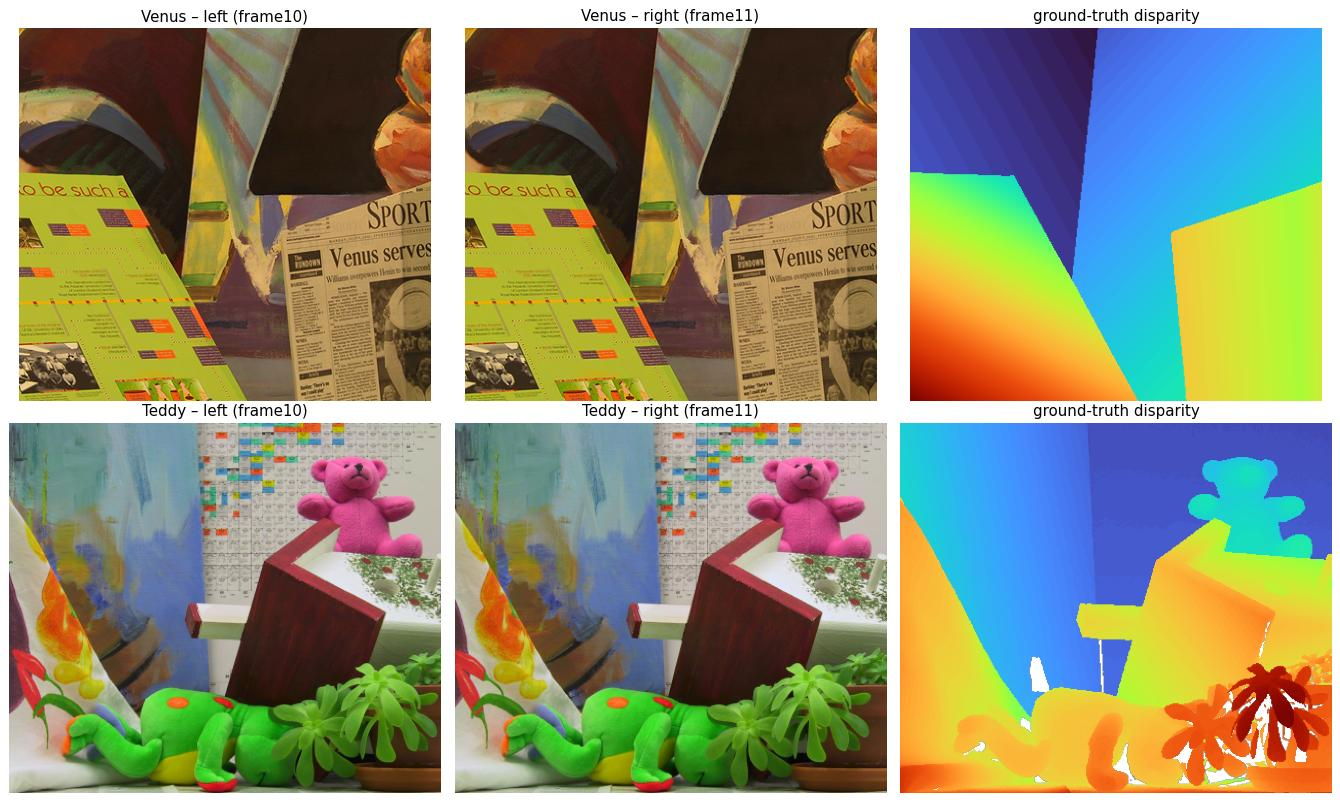

In [15]:
# Load images
scenes = {}
for s in SCENES:
    scenes[s] = load_scene(s)
    sc = scenes[s]
    rng = (np.nanmin(sc["gt"]), np.nanmax(sc["gt"])) if sc["gt"] is not None else None
    print(f"{s}: {sc['left'].shape[1]}x{sc['left'].shape[0]} – {sc['source']} – doffs {sc['doffs']} – GT range {rng}")

fig, axes = plt.subplots(len(scenes), 3, figsize=(15, 4.5 * len(scenes)))
for row, (s, sc) in zip(np.atleast_2d(axes), scenes.items()):
    row[0].imshow(bgr2rgb(sc["left"])); row[0].set_title(f"{s} – left (frame10)")
    row[1].imshow(bgr2rgb(sc["right"])); row[1].set_title(f"{s} – right (frame11)")
    if sc["gt"] is not None:
        row[2].imshow(sc["gt"], cmap="turbo"); row[2].set_title("ground-truth disparity")
    for ax in row:
        ax.axis("off")
save_fig(fig, os.path.join(out_b, "B0_input_pairs.png"))

### B.1 Fundamental matrix and epipolar lines

In [16]:
# Epipolar line functions
def sift_matches(left, right, ratio=0.75):
    sift = cv2.SIFT_create(nfeatures=4000)
    k1, d1 = sift.detectAndCompute(cv2.cvtColor(left, cv2.COLOR_BGR2GRAY), None)
    k2, d2 = sift.detectAndCompute(cv2.cvtColor(right, cv2.COLOR_BGR2GRAY), None)
    knn = cv2.BFMatcher(cv2.NORM_L2).knnMatch(d1, d2, k=2)
    good = [p[0] for p in knn if len(p) == 2 and p[0].distance < ratio * p[1].distance]
    return (np.float32([k1[m.queryIdx].pt for m in good]),
            np.float32([k2[m.trainIdx].pt for m in good]))

def draw_epilines(left, right, F, p1, p2, n=16, seed=3):
    rng = np.random.default_rng(seed)
    sel = rng.choice(len(p1), min(n, len(p1)), replace=False)
    a, b = left.copy(), right.copy()
    w = a.shape[1]
    lr = cv2.computeCorrespondEpilines(p1[sel].reshape(-1, 1, 2), 1, F).reshape(-1, 3)
    ll = cv2.computeCorrespondEpilines(p2[sel].reshape(-1, 1, 2), 2, F).reshape(-1, 3)
    cmap = plt.get_cmap("hsv")
    for i, j in enumerate(sel):
        col = tuple(int(255 * v) for v in cmap(i / len(sel))[:3][::-1])
        for img, (A, B, C), pt in ((b, lr[i], p2[j]), (a, ll[i], p1[j])):
            cv2.line(img, (0, int(round(-C / B))), (w, int(round(-(C + A * w) / B))), col, 1, cv2.LINE_AA)
            cv2.circle(img, (int(pt[0]), int(pt[1])), 4, col, -1, cv2.LINE_AA)
    return a, b

def fundamental_study(left, right, out):
    p1, p2 = sift_matches(left, right)
    rows, Fs = [], {}
    for name, flag, thr in [("8-point (all matches)", cv2.FM_8POINT, None),
                            ("RANSAC (1 px)", cv2.FM_RANSAC, 1.0), ("LMedS", cv2.FM_LMEDS, None)]:
        t = {}
        with timer(t, "ms"):
            F, mask = (cv2.findFundamentalMat(p1, p2, flag) if thr is None
                       else cv2.findFundamentalMat(p1, p2, flag, thr, 0.999))
        F = F[:3] / F[2, 2]
        inl = mask.ravel().astype(bool) if flag != cv2.FM_8POINT else np.ones(len(p1), bool)
        err = epipolar_distance(F, p1, p2)
        samp = sampson_error(F, p1, p2)
        s = np.linalg.svd(F, compute_uv=False)
        Fs[name] = (F, inl)
        rows.append({"Method": name, "Matches": len(p1), "Inliers": int(inl.sum()),
                     "Inlier_%": 100.0 * inl.mean(), "Mean_epi_err_inliers_px": float(err[inl].mean()),
                     "Mean_Sampson_inliers_px": float(samp[inl].mean()),
                     "Median_epi_err_all_px": float(np.median(err)),
                     "Mean_abs_line_angle_deg": float(np.abs(epipolar_line_angle(F, p1[inl])).mean()),
                     "Rank2_s3/s1": float(s[2] / s[0]), "Time_ms": t["ms"]})
    write_table(rows, os.path.join(out, "fundamental_matrix_metrics"), float_fmt="{:.4g}")
    F_r, inl_r = Fs["RANSAC (1 px)"]
    np.savetxt(os.path.join(out, "F_ransac.txt"), F_r, fmt="%.6e")

    fig, axes = plt.subplots(3, 2, figsize=(12, 15))
    for row_axes, (name, (F, inl)), r in zip(axes, Fs.items(), rows):
        a, b = draw_epilines(left, right, F, p1[inl_r], p2[inl_r])   # same points for every F
        row_axes[0].imshow(bgr2rgb(a)); row_axes[1].imshow(bgr2rgb(b))
        row_axes[0].set_title(f"{name} – left")
        row_axes[1].set_title(f"right | inliers {r['Inliers']}/{r['Matches']} | "
                              f"err {r['Mean_epi_err_inliers_px']:.2f}px | tilt {r['Mean_abs_line_angle_deg']:.1f}°")
        for ax in row_axes:
            ax.axis("off")
    fig.suptitle("Epipolar lines from the estimated fundamental matrix", fontweight="bold")
    save_fig(fig, os.path.join(out, "B4_epipolar_lines_comparison.png"))
    a, b = draw_epilines(left, right, F_r, p1[inl_r], p2[inl_r], n=20)
    cv2.imwrite(os.path.join(out, "B5_epipolar_lines_ransac.png"), np.hstack([a, b]))
    return rows

**Venus**

,Method,Matches,Inliers,Inlier_%,Mean_epi_err_inliers_px,Mean_Sampson_inliers_px,Median_epi_err_all_px,Mean_abs_line_angle_deg,Rank2_s3/s1,Time_ms
0,8-point (all matches),411,411,100.000,2.825,1.810,1.045,45.373,5.797e-18,0.209
1,RANSAC (1 px),411,381,92.701,0.233,0.165,0.172,6.174,3.084e-17,0.814
2,LMedS,411,328,79.805,0.066,0.047,0.067,1.522,1.127e-17,27.643


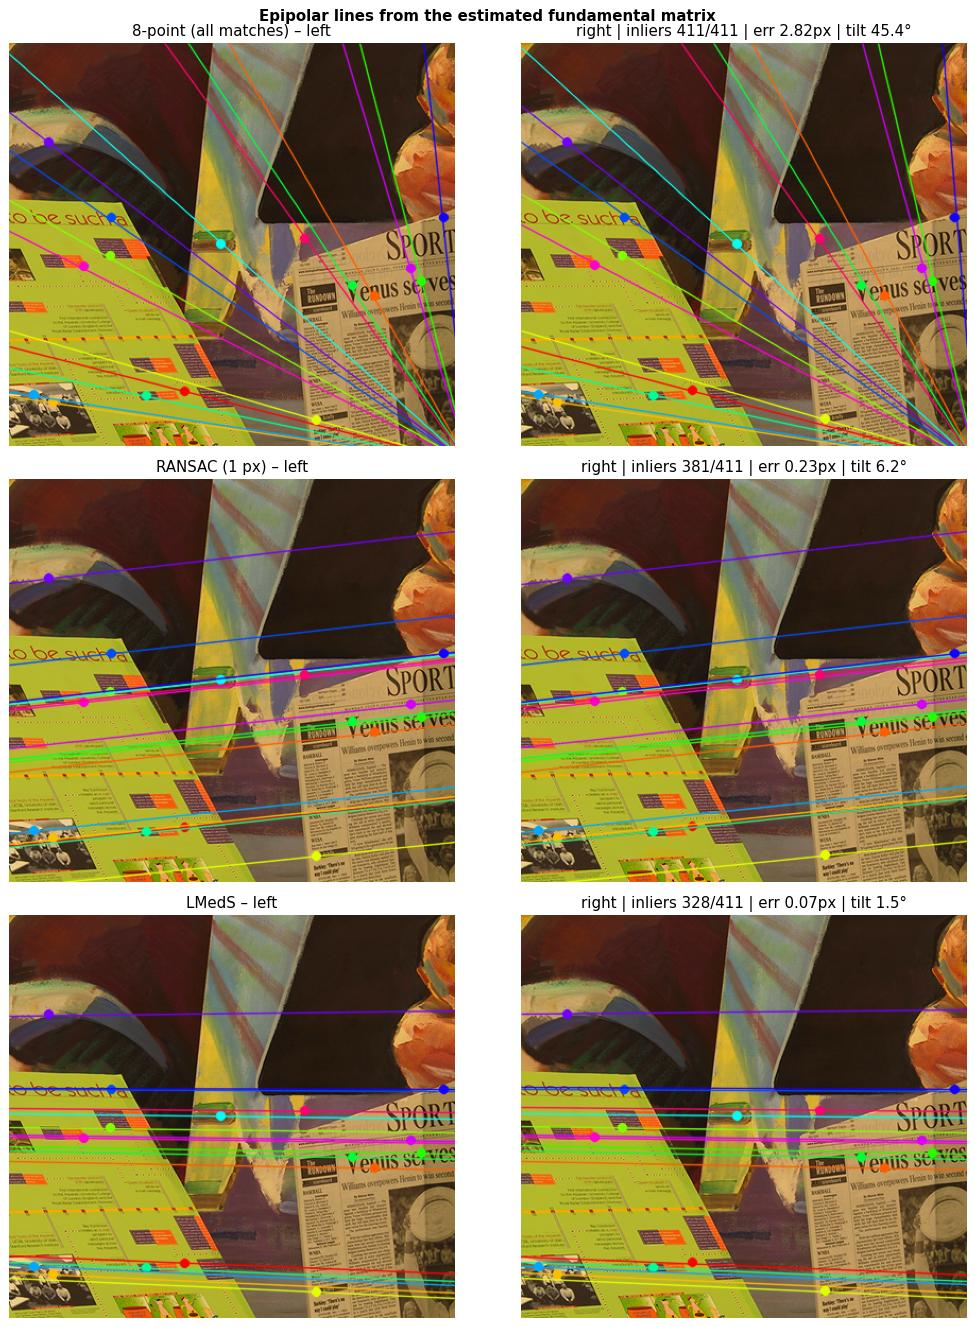

**Teddy**

,Method,Matches,Inliers,Inlier_%,Mean_epi_err_inliers_px,Mean_Sampson_inliers_px,Median_epi_err_all_px,Mean_abs_line_angle_deg,Rank2_s3/s1,Time_ms
0,8-point (all matches),353,353,100.000,2.202,1.538,1.154,36.095,2.393e-20,0.215
1,RANSAC (1 px),353,286,81.020,0.262,0.185,0.265,5.231,1.535e-17,2.520
2,LMedS,353,285,80.737,0.113,0.080,0.114,0.990,4.628e-19,27.758


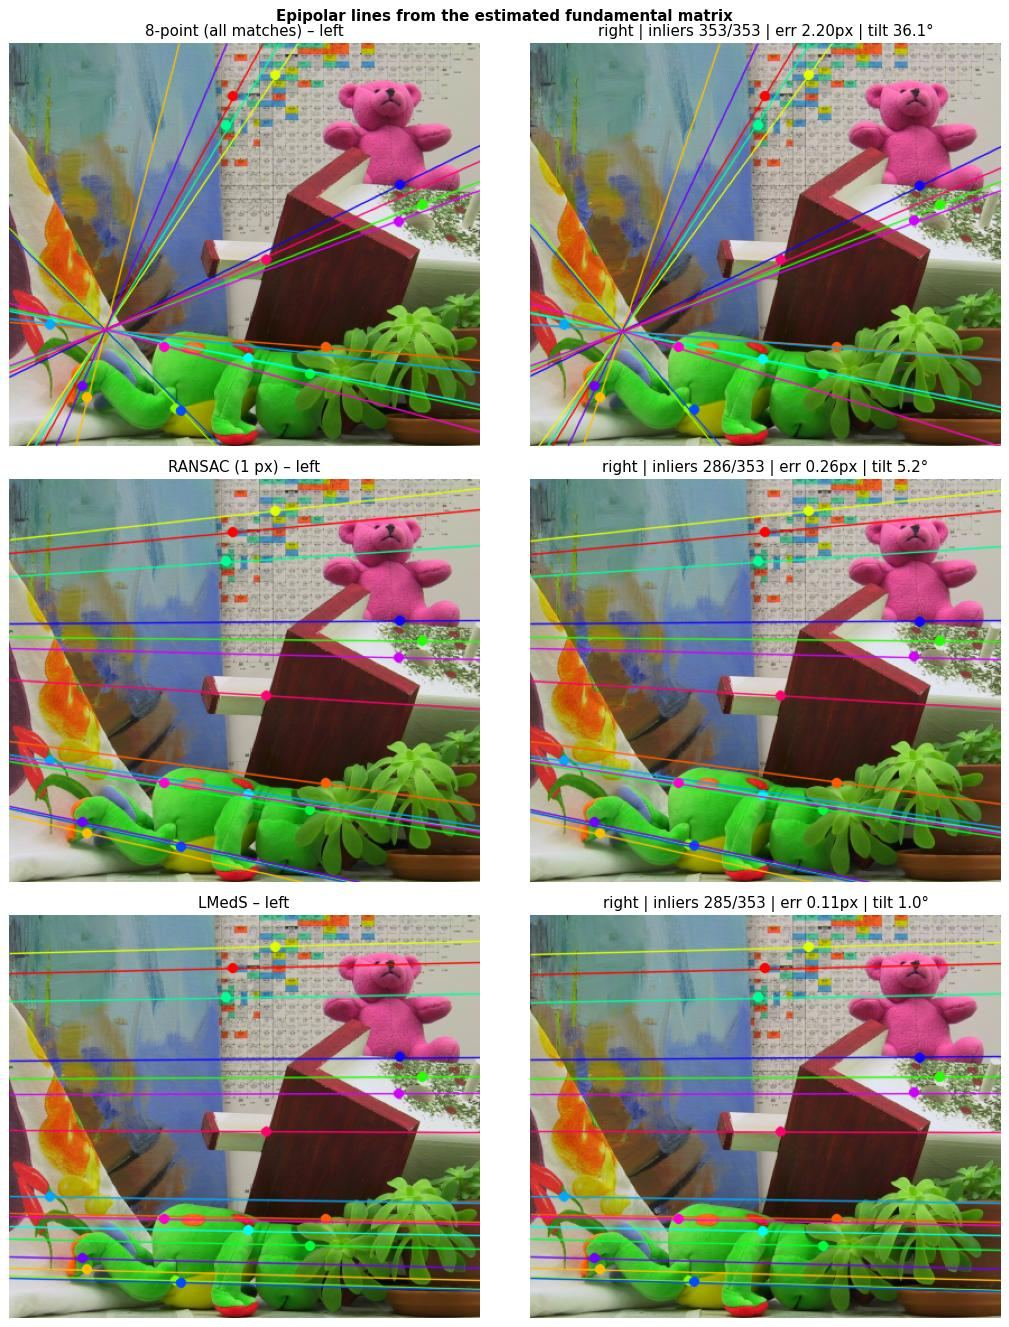

In [17]:
# Run epipolar line estimation: 8-point vs RANSAC vs LMedS
f_rows = []
for s, sc in scenes.items():
    display(Markdown(f"**{s}**"))
    out_s = out_dir(os.path.join("part_b", s.lower()))
    f_rows += [{"Scene": s, **r} for r in fundamental_study(sc["left"], sc["right"], out_s)]

### B.2 Disparity maps: BM vs SGBM

In [18]:
# Stereo matcher functions
def disparity_search_range(left, right, margin=4):
    """Estimate [minDisparity, minDisparity + numDisparities) from sparse SIFT matches that are
    consistent with the epipolar geometry (no ground truth needed)."""
    p1, p2 = sift_matches(left, right)
    _, mask = cv2.findFundamentalMat(p1, p2, cv2.FM_RANSAC, 1.0, 0.999)
    dx = (p1[:, 0] - p2[:, 0])[mask.ravel().astype(bool)]
    lo = int(np.floor(np.percentile(dx, 1))) - margin
    hi = int(np.ceil(np.percentile(dx, 99))) + margin
    num = int(np.ceil((hi - lo) / 16.0) * 16)
    return lo, num

def make_bm(block, num_disp, min_disp=0):
    """Block Matching: slide a block along the same row of the right image, keep the shift with
    the smallest Sum of Absolute Differences (local, winner-takes-all)."""
    bm = cv2.StereoBM_create(numDisparities=num_disp, blockSize=block)
    bm.setMinDisparity(min_disp)
    bm.setPreFilterCap(31)
    bm.setTextureThreshold(10)
    bm.setUniquenessRatio(10)
    bm.setSpeckleWindowSize(100)
    bm.setSpeckleRange(32)
    return bm

def make_sgbm(block, num_disp, min_disp=0):
    """Semi-Global Matching: minimise E(D) = Σ C(p,D_p) + Σ P1·[|ΔD|=1] + Σ P2·[|ΔD|>1],
    aggregating the cost along 8 directions -> dense, piecewise-smooth disparity."""
    return cv2.StereoSGBM_create(
        minDisparity=min_disp, numDisparities=num_disp, blockSize=block,
        P1=8 * 3 * block ** 2, P2=32 * 3 * block ** 2, disp12MaxDiff=1, uniquenessRatio=10,
        speckleWindowSize=100, speckleRange=32, preFilterCap=63, mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)

def compute_disparity(matcher, left, right, is_bm):
    """Float disparity in pixels; pixels without a valid match are NaN."""
    if is_bm:
        left, right = cv2.cvtColor(left, cv2.COLOR_BGR2GRAY), cv2.cvtColor(right, cv2.COLOR_BGR2GRAY)
    d = matcher.compute(left, right).astype(np.float32) / 16.0   # OpenCV returns fixed point ×16
    d[d < matcher.getMinDisparity()] = np.nan                     # invalid = minDisparity − 1
    return d

def right_disparity(matcher, left, right, is_bm):
    """Disparity referenced to the right image (mirror trick) – needed for the LR check."""
    return cv2.flip(compute_disparity(matcher, cv2.flip(right, 1), cv2.flip(left, 1), is_bm), 1)

def run_matchers(name, sc):
    """BM (blocks 9, 15) and SGBM (blocks 3, 7) with the SIFT-estimated range; returns rows, maps."""
    min_disp, num_disp = disparity_search_range(sc["left"], sc["right"])
    print(f"  {name}: disparity search range [{min_disp}, {min_disp + num_disp}) estimated from SIFT matches")
    configs = [("BM block=9", make_bm(9, num_disp, min_disp), True),
               ("BM block=15", make_bm(15, num_disp, min_disp), True),
               ("SGBM block=3", make_sgbm(3, num_disp, min_disp), False),
               ("SGBM block=7", make_sgbm(7, num_disp, min_disp), False)]
    rows, disps = [], {}
    for cname, m, is_bm in configs:
        compute_disparity(m, sc["left"], sc["right"], is_bm)          # warm-up for fair timing
        t = {}
        with timer(t, "ms"):
            d = compute_disparity(m, sc["left"], sc["right"], is_bm)
        dr = right_disparity(m, sc["left"], sc["right"], is_bm)
        disps[cname] = d
        rows.append({"Scene": name, "Method": cname, "Range": f"[{min_disp},{min_disp + num_disp})",
                     **stereo_report(d, sc["gt"], sc["valid"], dr), "Time_ms": t["ms"]})
    return rows, disps

def disparity_figure(name, sc, rows, disps, path):
    gt = sc["gt"]
    vals = np.concatenate([d[np.isfinite(d)] for d in disps.values()] + ([gt[sc["valid"]]] if gt is not None else []))
    vmin, vmax = np.percentile(vals, 1), np.percentile(vals, 99.5)
    cmap = plt.get_cmap("turbo").copy()
    cmap.set_bad("black")
    fig, axes = plt.subplots(3, 3, figsize=(15, 13))
    axes[0, 0].imshow(bgr2rgb(sc["left"])); axes[0, 0].set_title("Left (frame10)")
    axes[0, 1].imshow(bgr2rgb(sc["right"])); axes[0, 1].set_title("Right (frame11)")
    if gt is not None:
        axes[0, 2].imshow(gt, cmap=cmap, vmin=vmin, vmax=vmax); axes[0, 2].set_title("Ground-truth disparity")
    for ax, (cname, d), r in zip(axes[1:].ravel()[:4], disps.items(), rows):
        ax.imshow(d, cmap=cmap, vmin=vmin, vmax=vmax)
        txt = f"{cname}\nvalid {r['Valid_%']:.0f}%"
        if gt is not None:
            txt += f" | bad>1px {r['Bad1.0_%']:.1f}% | EPE {r['EPE_px']:.2f}"
        ax.set_title(txt, fontsize=10)
    if gt is not None:   # error maps of the best BM and the best SGBM configuration
        for ax, fam in ((axes[2, 1], "BM"), (axes[2, 2], "SGBM")):
            best = min((r for r in rows if r["Method"].startswith(fam + " ")), key=lambda r: r["Bad1.0_%"])
            im = ax.imshow(np.abs(disps[best["Method"]] - gt), cmap="inferno", vmin=0, vmax=4)
            ax.set_title(f"|d − d_gt| of {best['Method']} (px)")
            fig.colorbar(im, ax=ax, fraction=0.04)
    for ax in axes.ravel():
        ax.axis("off")
    fig.suptitle(f"{name}: BM vs SGBM disparity (black = no estimate)", fontweight="bold")
    save_fig(fig, path)

  Venus: disparity search range [-11, 21) estimated from SIFT matches


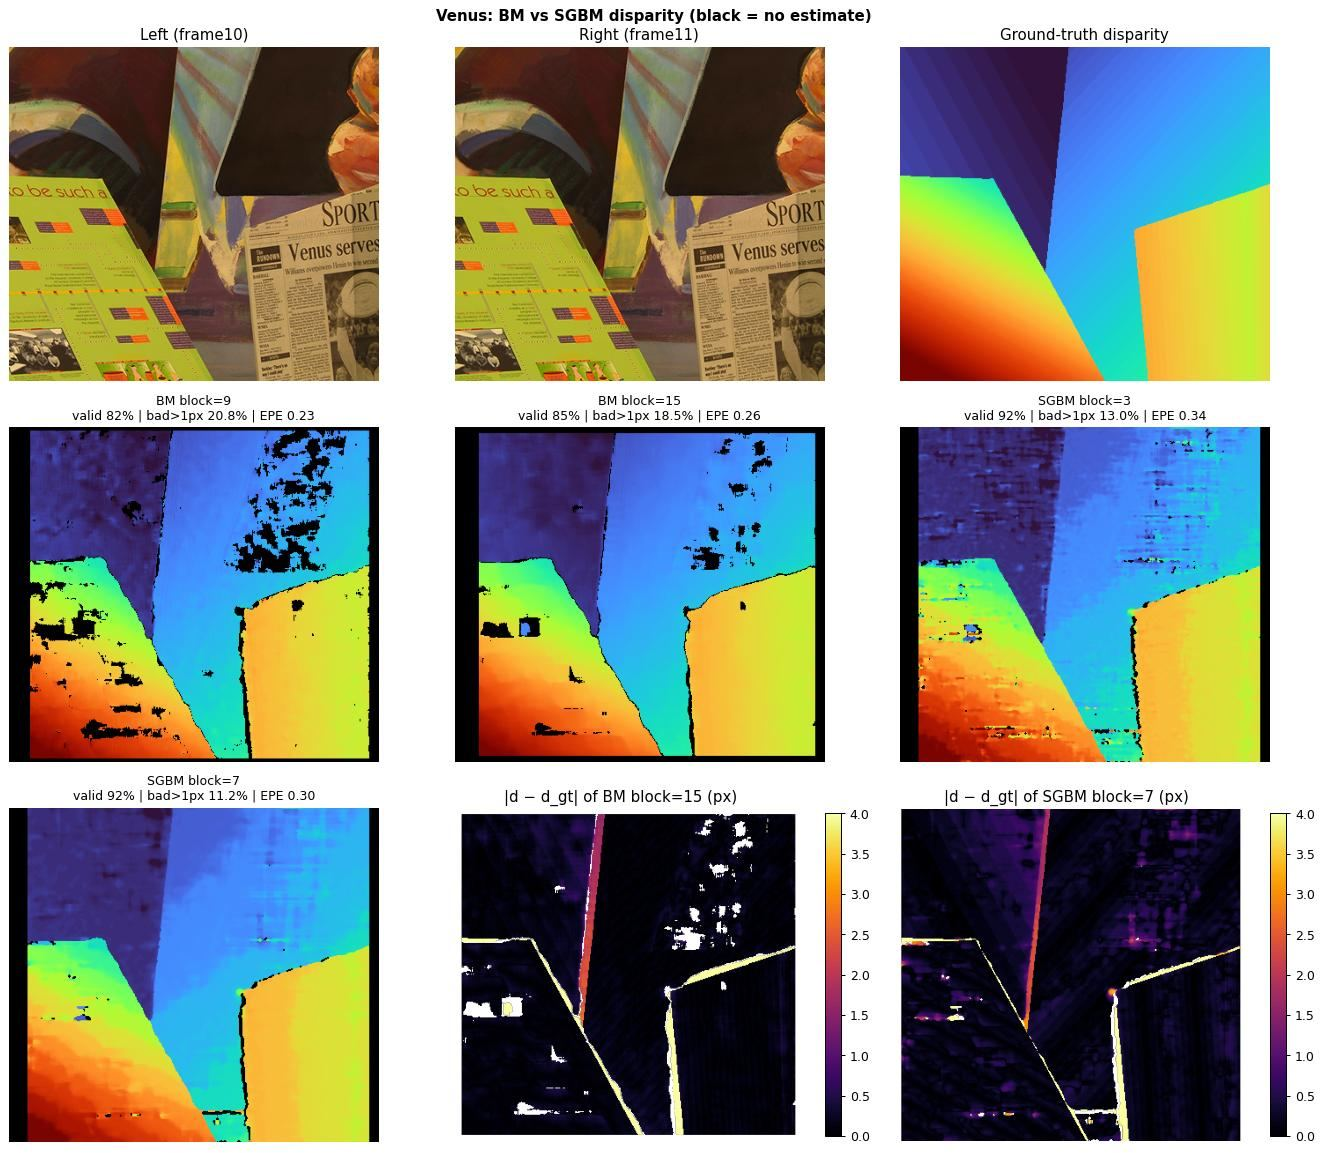

  Teddy: disparity search range [-15, 33) estimated from SIFT matches


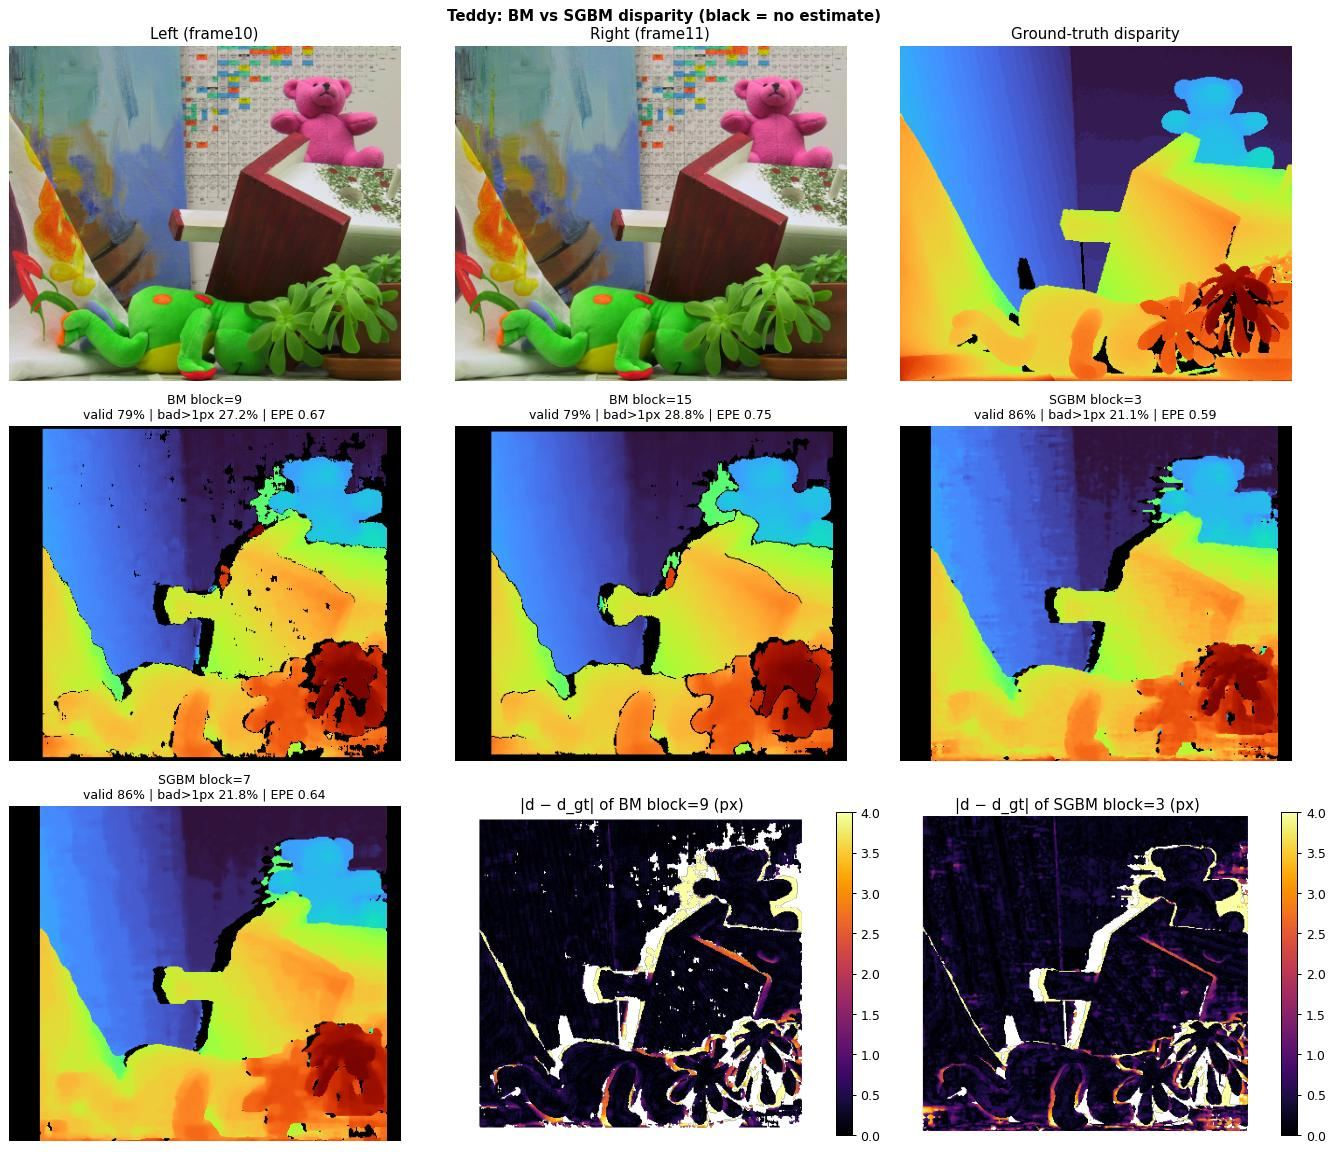

,Scene,Method,Range,Valid_%,LR_consistency_%,Bad1.0_%,Bad2.0_%,Bad1.0_on_estimated_%,EPE_px,RMSE_px,Time_ms
0,Venus,BM block=9,"[-11,21)",81.573,93.407,20.758,20.268,2.857,0.235,0.735,6.974
1,Venus,BM block=15,"[-11,21)",84.640,94.255,18.500,17.853,3.710,0.255,0.844,6.409
2,Venus,SGBM block=3,"[-11,21)",91.513,95.407,13.049,10.641,4.986,0.340,0.759,10.986
3,Venus,SGBM block=7,"[-11,21)",91.717,96.320,11.209,10.267,3.190,0.303,0.742,12.300
4,Teddy,BM block=9,"[-15,33)",78.915,92.041,27.190,26.002,7.900,0.670,2.500,8.548
5,Teddy,BM block=15,"[-15,33)",78.642,91.143,28.821,27.543,9.402,0.750,2.473,8.125
6,Teddy,SGBM block=3,"[-15,33)",86.119,93.686,21.050,18.776,8.138,0.593,1.808,15.780
7,Teddy,SGBM block=7,"[-15,33)",85.974,93.800,21.849,19.620,8.901,0.635,1.938,17.262


In [19]:
# Run BM and SGBM (two block sizes each) and score them against the ground truth
disp_rows, all_disps = [], {}
for s, sc in scenes.items():
    rows, disps = run_matchers(s, sc)
    all_disps[s] = disps
    disp_rows += rows
    out_s = out_dir(os.path.join("part_b", s.lower()))
    disparity_figure(s, sc, rows, disps, os.path.join(out_s, "B1_disparity_comparison.png"))
df_disp = write_table(disp_rows, os.path.join(out_b, "disparity_metrics_all_scenes"))

### B.2b Parameter study: blockSize and numDisparities

**Venus**

,Scene,Algorithm,Parameter,Value,Range,Valid_%,Bad1.0_%,Bad2.0_%,Bad1.0_on_estimated_%,EPE_px,RMSE_px,Time_ms
0,Venus,BM,blockSize,5,"[-11,21)",71.099,30.952,30.330,2.885,0.256,0.693,7.736
1,Venus,BM,blockSize,9,"[-11,21)",81.573,20.758,20.268,2.857,0.235,0.735,6.832
2,Venus,BM,blockSize,15,"[-11,21)",84.640,18.500,17.853,3.710,0.255,0.844,6.369
3,Venus,BM,blockSize,21,"[-11,21)",83.952,19.721,18.840,4.376,0.275,0.902,6.546
4,Venus,SGBM,blockSize,3,"[-11,21)",91.513,13.049,10.641,4.986,0.340,0.759,10.141
5,Venus,SGBM,blockSize,5,"[-11,21)",91.486,11.729,10.350,3.514,0.308,0.724,10.248
6,Venus,SGBM,blockSize,7,"[-11,21)",91.717,11.209,10.267,3.190,0.303,0.742,9.651
7,Venus,SGBM,blockSize,11,"[-11,21)",91.555,11.960,11.293,3.839,0.337,0.890,10.857
8,Venus,BM,numDisparities,16,"[-11,5)",82.241,21.424,20.792,4.457,0.338,1.130,5.819
9,Venus,BM,numDisparities,32,"[-11,21)",81.573,20.758,20.268,2.857,0.235,0.735,6.844


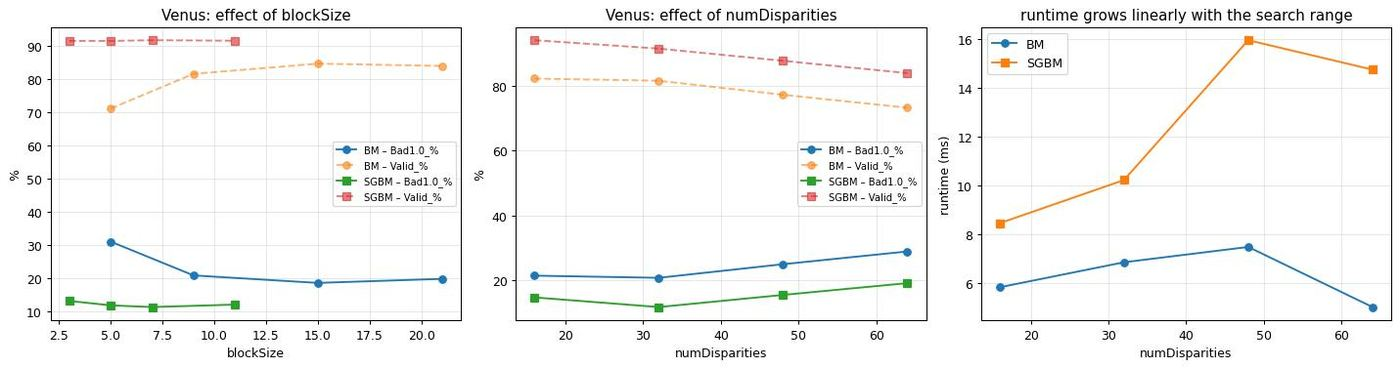

**Teddy**

,Scene,Algorithm,Parameter,Value,Range,Valid_%,Bad1.0_%,Bad2.0_%,Bad1.0_on_estimated_%,EPE_px,RMSE_px,Time_ms
0,Teddy,BM,blockSize,5,"[-15,33)",71.769,32.936,31.702,6.908,0.618,2.259,8.208
1,Teddy,BM,blockSize,9,"[-15,33)",78.915,27.190,26.002,7.900,0.670,2.500,7.456
2,Teddy,BM,blockSize,15,"[-15,33)",78.642,28.821,27.543,9.402,0.750,2.473,7.225
3,Teddy,BM,blockSize,21,"[-15,33)",76.974,31.082,29.869,10.279,0.801,2.450,7.182
4,Teddy,SGBM,blockSize,3,"[-15,33)",86.119,21.050,18.776,8.138,0.593,1.808,25.907
5,Teddy,SGBM,blockSize,5,"[-15,33)",86.065,21.337,19.186,8.397,0.608,1.864,10.660
6,Teddy,SGBM,blockSize,7,"[-15,33)",85.974,21.849,19.620,8.901,0.635,1.938,11.438
7,Teddy,SGBM,blockSize,11,"[-15,33)",85.597,24.179,21.829,11.221,0.839,2.545,13.414
8,Teddy,BM,numDisparities,16,"[-15,1)",56.027,58.942,58.767,27.378,3.433,7.346,6.087
9,Teddy,BM,numDisparities,32,"[-15,17)",83.157,23.698,22.233,8.488,0.716,2.535,9.466


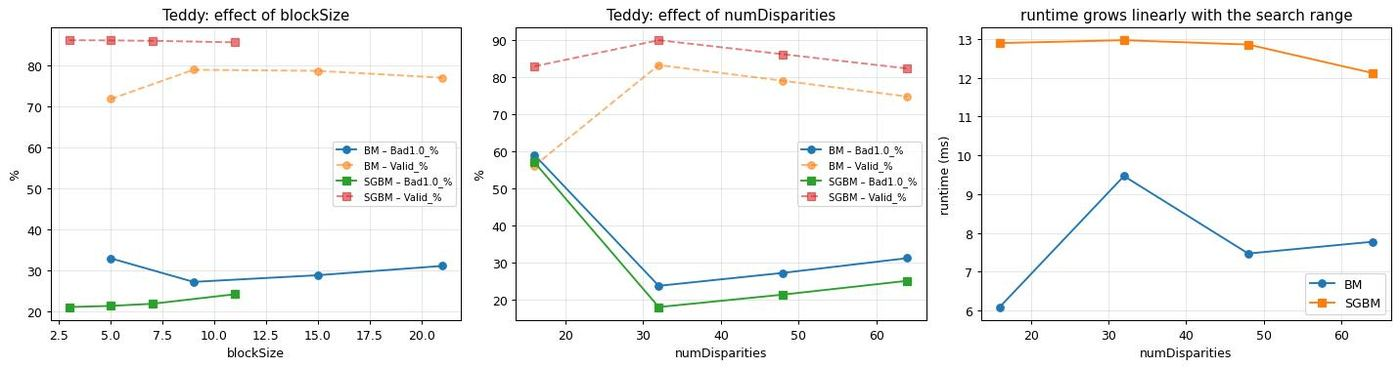

In [20]:
def parameter_study(name, sc, out):
    """Sensitivity of BM / SGBM to blockSize and numDisparities (other parameters fixed)."""
    lo, num = disparity_search_range(sc["left"], sc["right"])
    rows = []
    settings = ([("BM", "blockSize", b, make_bm(b, num, lo), True) for b in (5, 9, 15, 21)] +
                [("SGBM", "blockSize", b, make_sgbm(b, num, lo), False) for b in (3, 5, 7, 11)] +
                [("BM", "numDisparities", n, make_bm(9, n, lo), True) for n in (16, 32, 48, 64)] +
                [("SGBM", "numDisparities", n, make_sgbm(5, n, lo), False) for n in (16, 32, 48, 64)])
    for algo, param, val, m, is_bm in settings:
        compute_disparity(m, sc["left"], sc["right"], is_bm)
        t = {}
        with timer(t, "ms"):
            d = compute_disparity(m, sc["left"], sc["right"], is_bm)
        rep = stereo_report(d, sc["gt"], sc["valid"])
        rows.append({"Scene": name, "Algorithm": algo, "Parameter": param, "Value": val,
                     "Range": f"[{lo},{lo + (num if param == 'blockSize' else val)})", **rep, "Time_ms": t["ms"]})
    write_table(rows, os.path.join(out, "parameter_study"))

    metric = "Bad1.0_%" if sc["gt"] is not None else "Valid_%"
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
    for ax, param in zip(axes[:2], ("blockSize", "numDisparities")):
        for algo, mk in (("BM", "o-"), ("SGBM", "s-")):
            sub = [r for r in rows if r["Algorithm"] == algo and r["Parameter"] == param]
            ax.plot([r["Value"] for r in sub], [r[metric] for r in sub], mk, label=f"{algo} – {metric}")
            ax.plot([r["Value"] for r in sub], [r["Valid_%"] for r in sub], mk.replace("-", "--"), alpha=0.6,
                    label=f"{algo} – Valid_%")
        ax.set_xlabel(param); ax.set_ylabel("%"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
        ax.set_title(f"{name}: effect of {param}")
    for algo, mk in (("BM", "o-"), ("SGBM", "s-")):
        sub = [r for r in rows if r["Algorithm"] == algo and r["Parameter"] == "numDisparities"]
        axes[2].plot([r["Value"] for r in sub], [r["Time_ms"] for r in sub], mk, label=algo)
    axes[2].set_xlabel("numDisparities"); axes[2].set_ylabel("runtime (ms)"); axes[2].grid(alpha=0.3)
    axes[2].legend(); axes[2].set_title("runtime grows linearly with the search range")
    save_fig(fig, os.path.join(out, "B3_parameter_study.png"))
    return rows

for s, sc in scenes.items():
    display(Markdown(f"**{s}**"))
    parameter_study(s, sc, out_dir(os.path.join("part_b", s.lower())))

### B.3 3D point cloud (interactive – drag to rotate, scroll to zoom)

In [21]:
# Point cloud functions
def disparity_to_points(disp, img, focal, baseline, doffs=0.0):
    """Triangulation with Middlebury's convention Z = f·B / (d + doffs)."""
    h, w = disp.shape
    cx, cy = w / 2.0, h / 2.0
    # [X Y Z W]ᵀ = Q [u v d 1]ᵀ  ->  W = (d + doffs)/B,  Z = f/W
    Q = np.float32([[1, 0, 0, -cx], [0, 1, 0, -cy], [0, 0, 0, focal], [0, 0, 1.0 / baseline, doffs / baseline]])
    d = np.nan_to_num(disp, nan=-1e6).astype(np.float32)
    pts = cv2.reprojectImageTo3D(d, Q)
    mask = np.isfinite(disp) & (disp + doffs > 1.0)
    xyz, rgb = pts[mask], bgr2rgb(img)[mask]
    keep = np.isfinite(xyz).all(1) & (xyz[:, 2] < np.percentile(xyz[:, 2], 99))
    return xyz[keep], rgb[keep], Q

def write_ply(path, xyz, rgb):
    """Binary PLY – open with MeshLab (File > Import Mesh), CloudCompare or Open3D."""
    v = np.empty(len(xyz), dtype=[("x", "<f4"), ("y", "<f4"), ("z", "<f4"),
                                  ("red", "u1"), ("green", "u1"), ("blue", "u1")])
    v["x"], v["y"], v["z"] = xyz.T
    v["red"], v["green"], v["blue"] = rgb.T
    header = (f"ply\nformat binary_little_endian 1.0\nelement vertex {len(xyz)}\n"
              "property float x\nproperty float y\nproperty float z\n"
              "property uchar red\nproperty uchar green\nproperty uchar blue\nend_header\n")
    with open(path, "wb") as f:
        f.write(header.encode("ascii"))
        f.write(v.tobytes())

def interactive_point_cloud(xyz, rgb, path, title, n_max=50000):
    """Plotly HTML: open in any browser and rotate/zoom with the mouse (works in Colab too)."""
    try:
        import plotly.graph_objects as go
    except ImportError:
        print("  plotly not installed -> skip interactive HTML (pip install plotly)")
        return None
    idx = np.random.default_rng(0).choice(len(xyz), min(n_max, len(xyz)), replace=False)
    p, c = xyz[idx], rgb[idx]
    colors = [f"rgb({r},{g},{b})" for r, g, b in c]
    fig = go.Figure(go.Scatter3d(x=p[:, 0], y=p[:, 2], z=-p[:, 1], mode="markers",
                                 marker=dict(size=1.6, color=colors)))
    fig.update_layout(title=title, margin=dict(l=0, r=0, t=40, b=0),
                      scene=dict(xaxis_title="X", yaxis_title="Z (depth)", zaxis_title="−Y",
                                 aspectmode="data",
                                 camera=dict(eye=dict(x=0.0, y=-1.8, z=0.6))))
    fig.write_html(path, include_plotlyjs="cdn")   # small file; needs internet to load plotly.js
    return fig

def static_views(xyz, rgb, path, title, n_max=60000):
    """Three fixed viewpoints of the same cloud, for the PDF report."""
    idx = np.random.default_rng(0).choice(len(xyz), min(n_max, len(xyz)), replace=False)
    p, c = xyz[idx], rgb[idx] / 255.0
    fig = plt.figure(figsize=(16, 5.5))
    for i, (elev, azim, name) in enumerate([(0, -90, "Front"), (25, -60, "Oblique"), (89, -90, "Top (X–Z)")], 1):
        ax = fig.add_subplot(1, 3, i, projection="3d")
        ax.scatter(p[:, 0], p[:, 2], -p[:, 1], c=c, s=0.8, linewidths=0, depthshade=False)
        ax.view_init(elev=elev, azim=azim)
        ax.set_xlabel("X"); ax.set_ylabel("Z (depth)"); ax.set_zlabel("−Y")
        ax.set_title(name)
    fig.suptitle(title, fontweight="bold")
    save_fig(fig, path)

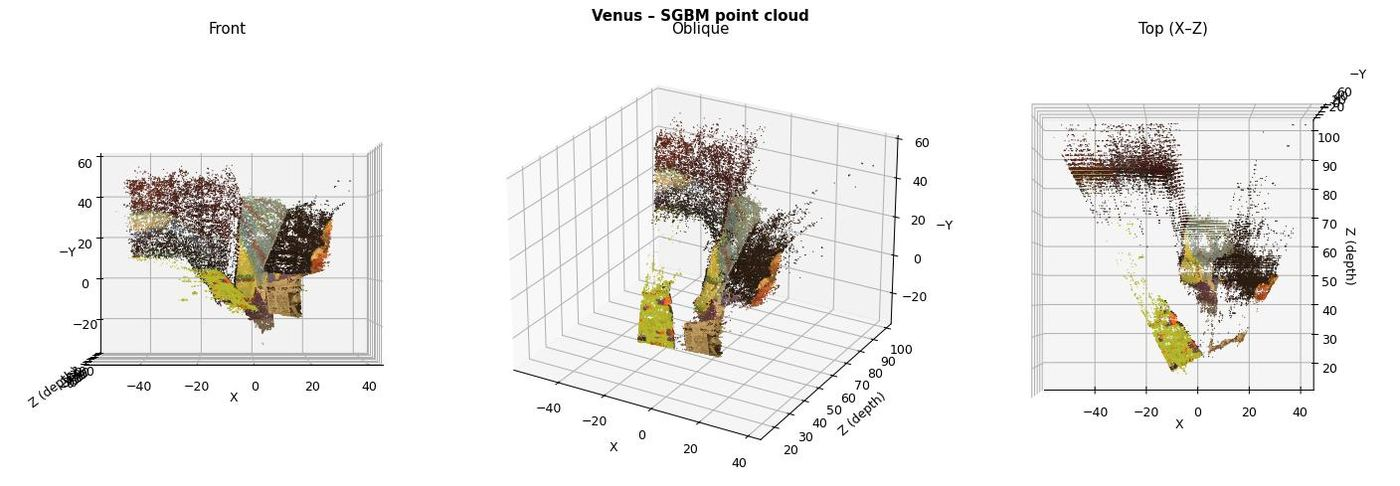

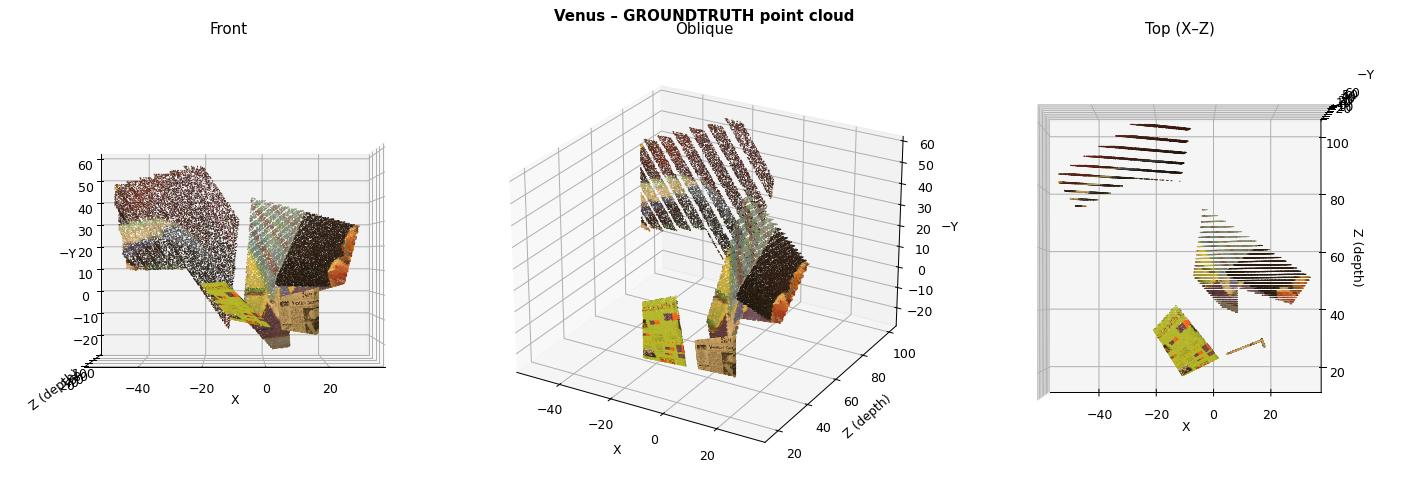

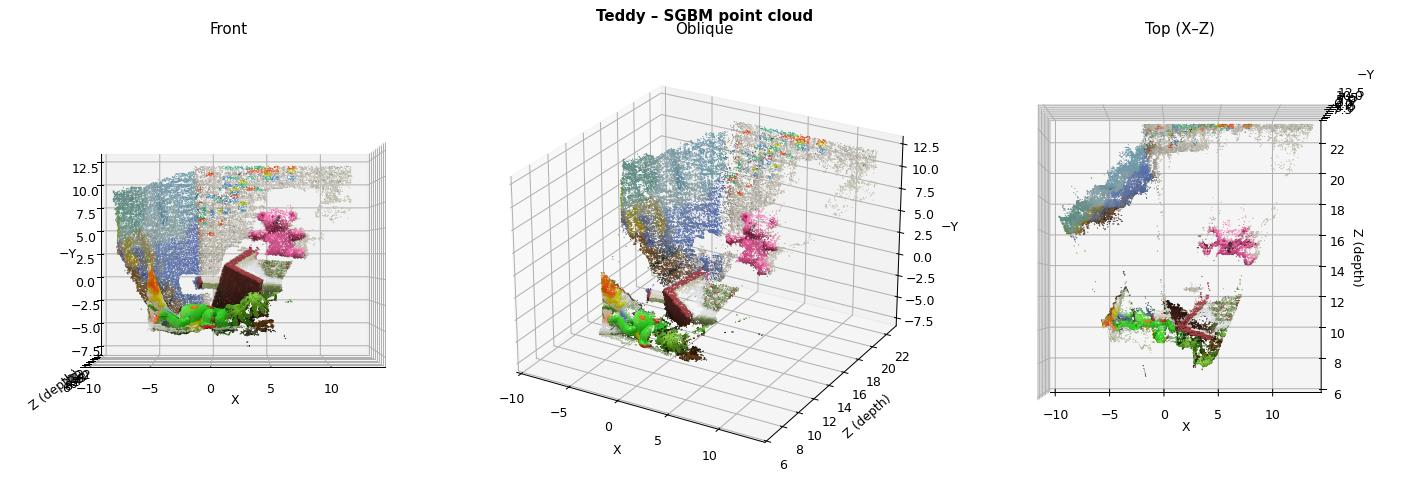

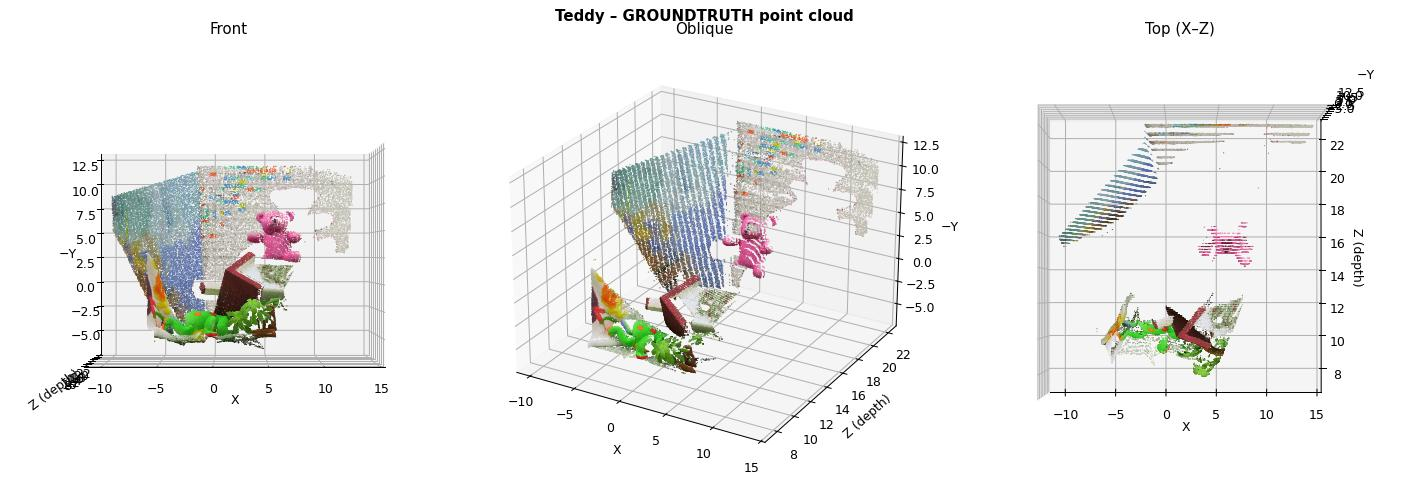

Q matrix (Teddy):
 [[   1.    0.    0. -210.]
 [   0.    1.    0. -180.]
 [   0.    0.    0.  336.]
 [   0.    0.    1.   26.]]


In [22]:
# Build point clouds from SGBM, BM and ground truth; save .ply (MeshLab / Open3D) + interactive .html
figs3d = {}
for s, sc in scenes.items():
    out_s = out_dir(os.path.join("part_b", s.lower()))
    clouds = {"sgbm": all_disps[s]["SGBM block=3"], "bm": all_disps[s]["BM block=9"]}
    if sc["gt"] is not None:
        clouds["groundtruth"] = sc["gt"]
    for tag, disp in clouds.items():
        xyz, rgb, Q = disparity_to_points(disp, sc["left"], FOCAL_SCALE * sc["left"].shape[1], BASELINE, sc["doffs"])
        write_ply(os.path.join(out_s, f"point_cloud_{tag}.ply"), xyz, rgb)
        figs3d[(s, tag)] = interactive_point_cloud(
            xyz, rgb, os.path.join(out_s, f"B2_point_cloud_{tag}_interactive.html"),
            f"{s} – point cloud from {tag.upper()} disparity ({len(xyz):,} points)")
        if tag != "bm":
            static_views(xyz, rgb, os.path.join(out_s, f"B2_point_cloud_{tag}.png"), f"{s} – {tag.upper()} point cloud")
    np.savetxt(os.path.join(out_s, "Q_matrix.txt"), Q, fmt="%.5f")
print("Q matrix (Teddy):\n", Q)

In [23]:
# Interactive 3D view (rotate with the mouse). The same file can be opened in a browser:
# results/part_b/venus/B2_point_cloud_sgbm_interactive.html  – or the .ply in MeshLab
import plotly.io as pio
pio.renderers.default = "notebook_connected"
figs3d[("Venus", "sgbm")].show()

In [24]:
figs3d[("Teddy", "sgbm")].show()

### Part B – Comparative analysis
* **Valid ratio vs accuracy**: BM is very accurate where it answers (Venus: 2.9 % bad pixels among estimated ones,
  lowest EPE 0.23 px) but only 82–85 % of the pixels are valid, so its Bad-1.0 is 18.5–20.8 %. SGBM's smoothness
  term gives ≈ 92 % valid pixels and Bad-1.0 11.2 % (block 7).
* **Teddy** (occlusions, thin leaves): SGBM wins on every ground-truth metric (Bad-1.0 21.1 % vs 27.2 %, EPE 0.59
  vs 0.67 px).
* **blockSize**: BM needs large windows (5 → 15 raises the valid ratio 71 → 85 % on Venus) but larger windows fatten
  borders; for SGBM 5–7 is best on Venus and 3 on Teddy; 11 over-smooths.
* **numDisparities**: the range must cover the true disparities (16 truncates Teddy → Bad-1.0 57 %), but every extra
  16 disparities adds a 16-pixel invalid band at the left border, so a range that is too large also hurts
  (Venus SGBM: 11.7 % at 32 → 19.1 % at 64). Runtime grows with the range.
* **Fundamental matrix**: 8-point on all matches is pulled by outliers (lines tilted 36–45°, Sampson 1.5–1.8 px).
  RANSAC reduces the Sampson error to 0.16–0.19 px and LMedS to 0.05–0.08 px with lines within 1–1.5° of
  horizontal; RANSAC (1 px) keeps a 5–6° tilt because both scenes are dominated by a few planes.
* **Point cloud**: the planes of Venus and the objects of Teddy appear at the correct relative depths.

## Part C: Multi-View Image Stitching (4 own photos)
### Input images
Four overlapping photos taken from my apartment window in Hanoi (iPhone 12, rotating the phone in place):
`data/own_photos/part_c/IMG_3111–IMG_3114.jpg`. The left-to-right order is found automatically.

### Pipeline
1. **Feature extraction** – SIFT vs ORB vs AKAZE
2. **Feature matching** – kNN (k = 2) + Lowe's ratio test (0.75), exact brute-force search
3. **Homography estimation** – RANSAC, thresholds 1 / 3 / 5 / 10 px compared
4. **Warping & blending** – planar vs cylindrical projection (focal length from EXIF), overwrite / feathering /
   multi-band (Laplacian pyramid) blending, tilt removal and crop to the largest rectangle → flat panorama

### Homography estimation (short explanation)
For a camera that only rotates (or a planar scene) two views are related by $x' \sim Hx$, $H$ is 3×3 with 8 degrees
of freedom. Each correspondence gives two linear equations, so ≥ 4 matches determine $H$ (**DLT**, solved with SVD
of $Ah=0$). Because some matches are wrong, **RANSAC** repeats: pick 4 random matches → compute $H$ → count inliers
with $\|x'-Hx\| <$ threshold → keep the $H$ with most inliers → refit on all its inliers.

### Metrics
keypoints, initial (ratio-test) matches, **inliers**, **inlier ratio %**, **mean reprojection RMSE** of the inliers,
**total stitching time (ms)**, plus overlap RMSE, black border %, straightness % and area kept after cropping.

In [25]:
# Parameters
RATIO = 0.75                          # Lowe ratio test
RANSAC_THR = 3.0                      # px (main pipeline)
RANSAC_THRESHOLDS = (1.0, 3.0, 5.0, 10.0)
DETECTORS = ("SIFT", "ORB", "AKAZE")
MAX_SIDE = 1200                       # working resolution
out_c = out_dir("part_c")

In [26]:
# Metric functions (Part C)
def inlier_ratio(mask):
    return float(100.0 * np.mean(mask))

def reprojection_errors(H, src, dst):
    """‖dst − H·src‖ for every correspondence [px]."""
    proj = cv2.perspectiveTransform(np.float32(src).reshape(-1, 1, 2), H).reshape(-1, 2)
    return np.linalg.norm(proj - dst, axis=1)

def reprojection_rmse(H, src, dst):
    e = reprojection_errors(H, src, dst)
    return float(np.sqrt(np.mean(e ** 2)))

def overlap_rmse(warped, masks):
    """Photometric RMSE between consecutive warped images inside their overlap
    (lower = better geometric alignment; also includes exposure differences)."""
    vals = []
    for i in range(len(warped) - 1):
        ov = (masks[i] > 0) & (masks[i + 1] > 0)
        if ov.sum() < 100:
            continue
        a = cv2.cvtColor(warped[i], cv2.COLOR_BGR2GRAY)[ov].astype(np.float32)
        b = cv2.cvtColor(warped[i + 1], cv2.COLOR_BGR2GRAY)[ov].astype(np.float32)
        vals.append(np.sqrt(np.mean((a - b) ** 2)))
    return float(np.mean(vals)) if vals else float("nan")

def black_border_ratio(pano):
    """% of the panorama's bounding box that is empty (black) – 0 after a perfect crop."""
    return float(100.0 * np.mean(pano.max(axis=2) == 0))

def straightness(pano):
    """How 'flat' the panorama is: vertical spread (px) of the top content edge relative to the
    height. A bow-tie / curved panorama has a large value, a flat one ≈ 0."""
    valid = pano.max(axis=2) > 0
    cols = np.where(valid.any(axis=0))[0]
    top = np.array([np.argmax(valid[:, c]) for c in cols])
    bottom = np.array([valid.shape[0] - 1 - np.argmax(valid[::-1, c]) for c in cols])
    spread = (np.percentile(top, 95) - np.percentile(top, 5) +
              np.percentile(bottom, 95) - np.percentile(bottom, 5)) / 2
    return float(100.0 * spread / pano.shape[0])

In [27]:
# Feature detection and matching
def detect(img, method, mask=None):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if method == "SIFT":       # DoG extrema + 128-D gradient histograms
        det = cv2.SIFT_create(nfeatures=6000)
    elif method == "ORB":      # oriented FAST + rotated BRIEF (256 bit)
        det = cv2.ORB_create(nfeatures=6000, scaleFactor=1.2, nlevels=8, fastThreshold=10)
    else:                      # AKAZE: nonlinear scale space + binary M-LDB descriptor
        det = cv2.AKAZE_create(threshold=0.0005)
    return det.detectAndCompute(gray, mask)

def match(d_query, d_train, method, ratio=RATIO):
    """kNN + ratio test: keep m only if dist(m) < ratio · dist(2nd best) (rejects ambiguous matches)."""
    # exact brute-force search (deterministic): L2 for SIFT's float descriptor, Hamming for binary ones
    matcher = cv2.BFMatcher(cv2.NORM_L2 if method == "SIFT" else cv2.NORM_HAMMING)
    knn = matcher.knnMatch(d_query, d_train, k=2)
    return [p[0] for p in knn if len(p) == 2 and p[0].distance < ratio * p[1].distance]

def pair_points(kq, kt, matches):
    return (np.float32([kq[m.queryIdx].pt for m in matches]),
            np.float32([kt[m.trainIdx].pt for m in matches]))

def auto_order(images, method="SIFT", min_inliers=25):
    """Find the left -> right order automatically, so file names do not matter.
    For every pair (i, j) with enough RANSAC inliers, dx_ij = median(x_i − x_j) of the matched
    points ≈ how far image j sits to the right of image i. Positions p are then solved by least
    squares (p_j − p_i = dx_ij, p_0 = 0) and the images are sorted by p."""
    n = len(images)
    feats = [detect(im, method) for im in images]
    eqs = []
    for i in range(n):
        for j in range(i + 1, n):
            good = match(feats[j][1], feats[i][1], method)
            if len(good) < 8:
                continue
            src, dst = pair_points(feats[j][0], feats[i][0], good)        # j -> i
            H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_THR)
            if mask is None or mask.sum() < min_inliers:
                continue
            inl = mask.ravel().astype(bool)
            eqs.append((i, j, float(np.median(dst[inl, 0] - src[inl, 0])), int(inl.sum())))
    A, b, wts = [], [], []
    for i, j, dx, w in eqs:
        row = np.zeros(n)
        row[j], row[i] = 1, -1
        A.append(row); b.append(dx); wts.append(np.sqrt(w))
    A.append(np.eye(n)[0]); b.append(0.0); wts.append(100.0)          # anchor p_0 = 0
    A, b, wts = np.array(A), np.array(b), np.array(wts)
    p = np.linalg.lstsq(A * wts[:, None], b * wts, rcond=None)[0]
    order = list(np.argsort(p))
    return order, p, eqs

def find_own_photos():
    files = [f for f in glob.glob(os.path.join(DATA_DIR, "own_photos", "part_c", "*"))
             if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"))]
    num = lambda p: [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", os.path.basename(p))]  # noqa: E731
    return sorted(files, key=num)

left -> right: ['IMG_3112.jpg', 'IMG_3111.jpg', 'IMG_3113.jpg', 'IMG_3114.jpg'] | size (675, 1200)


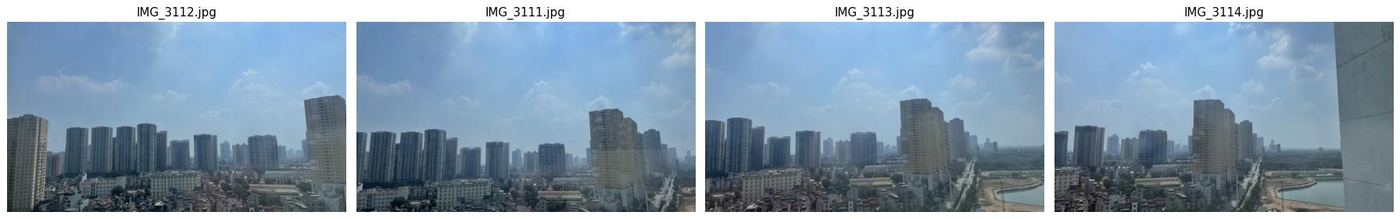

In [28]:
# Load my 4 photos and find the left -> right order automatically
paths = find_own_photos()
images = [resize_max(imread(p), MAX_SIDE) for p in paths]
order, pos, eqs = auto_order(images)
images, paths = [images[k] for k in order], [paths[k] for k in order]
print("left -> right:", [os.path.basename(p) for p in paths], "| size", images[0].shape[:2])
fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 3.4))
for ax, im, p in zip(axes, images, paths):
    ax.imshow(bgr2rgb(im)); ax.set_title(os.path.basename(p)); ax.axis("off")
save_fig(fig, os.path.join(out_c, "C0_input_photos.png"))

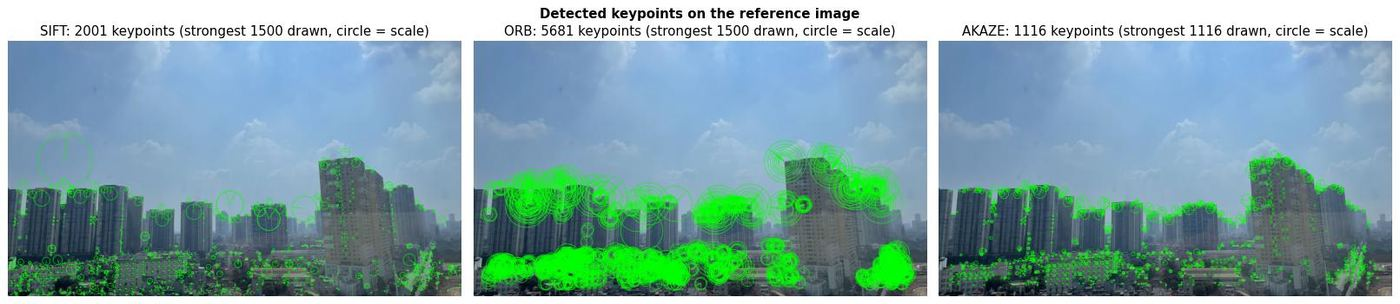

In [29]:
# Keypoint visualisation
def keypoint_figure(images, out, max_draw=1500):
    """Detected keypoints of every detector on the reference (middle) image."""
    ref = images[(len(images) - 1) // 2]
    fig, axes = plt.subplots(1, len(DETECTORS), figsize=(6 * len(DETECTORS), 6 * ref.shape[0] / ref.shape[1] + 0.6))
    for ax, det in zip(np.atleast_1d(axes), DETECTORS):
        kps, _ = detect(ref, det)
        strongest = sorted(kps, key=lambda k: -k.response)[:max_draw]
        vis = cv2.drawKeypoints(ref, strongest, None, color=(0, 255, 0),
                                flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        cv2.imwrite(os.path.join(out, f"C0_keypoints_{det}.jpg"), vis)
        ax.imshow(bgr2rgb(vis))
        ax.set_title(f"{det}: {len(kps)} keypoints (strongest {len(strongest)} drawn, circle = scale)")
        ax.axis("off")
    fig.suptitle("Detected keypoints on the reference image", fontweight="bold")
    save_fig(fig, os.path.join(out, "C0_keypoints.png"), dpi=110)

keypoint_figure(images, out_c)

In [30]:
# Focal length (EXIF / homography), cylindrical projection, warping
def focal_from_homography(H, w, h):
    """Szeliski & Shum (1997) closed form (same as OpenCV's detail::focalsFromHomography):
    for a purely rotating camera H = K R K⁻¹, so f can be read off H (in centred coordinates)."""
    T = np.array([[1, 0, w / 2], [0, 1, h / 2], [0, 0, 1]], np.float64)
    Hc = np.linalg.inv(T) @ H @ T
    Hc /= Hc[2, 2]
    h_ = Hc.ravel()
    fs = []
    # f1
    d1, d2 = h_[6] * h_[7], (h_[7] - h_[6]) * (h_[7] + h_[6])
    if abs(d1) > 1e-12 and abs(d2) > 1e-12:
        v1 = -(h_[0] * h_[1] + h_[3] * h_[4]) / d1
        v2 = (h_[0] ** 2 + h_[3] ** 2 - h_[1] ** 2 - h_[4] ** 2) / d2
        v1, v2 = max(v1, v2), min(v1, v2)
        if v1 > 0 and v2 > 0:
            fs.append(np.sqrt(v1 if abs(d1) > abs(d2) else v2))
        elif v1 > 0:
            fs.append(np.sqrt(v1))
    # f0
    d1 = h_[0] * h_[3] + h_[1] * h_[4]
    d2 = h_[0] ** 2 + h_[1] ** 2 - h_[3] ** 2 - h_[4] ** 2
    if abs(d1) > 1e-12 and abs(d2) > 1e-12:
        v1, v2 = -h_[2] * h_[5] / d1, (h_[5] ** 2 - h_[2] ** 2) / d2
        v1, v2 = max(v1, v2), min(v1, v2)
        if v1 > 0 and v2 > 0:
            fs.append(np.sqrt(v1 if abs(d1) > abs(d2) else v2))
        elif v1 > 0:
            fs.append(np.sqrt(v1))
    return float(np.sqrt(np.prod(fs))) if len(fs) == 2 else (fs[0] if fs else None)

def exif_focal_px(path, work_width):
    """Focal length in pixels from the photo's EXIF (35-mm equivalent focal length):
    f_px = f_35mm / 36 mm × long side (px), rescaled to the working resolution. None if absent."""
    try:
        from PIL import Image
        with Image.open(path) as im:
            f35 = im.getexif().get_ifd(0x8769).get(41989)
            w0, h0 = im.size
        if not f35:
            return None
        return float(f35) / 36.0 * max(w0, h0) * (work_width / w0)
    except Exception:
        return None

def estimate_focal(Hs_pair, w, h):
    cands = [focal_from_homography(H, w, h) for H in Hs_pair]
    cands = [f for f in cands if f is not None and 0.3 * max(w, h) < f < 5 * max(w, h)]
    if cands:
        return float(np.median(cands)), "estimated from homographies"
    return 0.75 * max(w, h), "fallback 0.75·max(w,h) (typical phone main camera)"

def cylindrical_warp(img, f):
    """Project an image onto a cylinder of radius f:  θ = (u−W/2)/f,  x = f·tanθ + cx,
    y = (v−cy)/cosθ + cy.  Returns the warped image and its validity mask."""
    h, w = img.shape[:2]
    cx, cy = w / 2.0, h / 2.0
    W = int(2 * f * np.arctan(cx / f))
    u, v = np.meshgrid(np.arange(W, dtype=np.float32), np.arange(h, dtype=np.float32))
    theta = (u - W / 2.0) / f
    map_x = (f * np.tan(theta) + cx).astype(np.float32)
    map_y = ((v - cy) / np.cos(theta) + cy).astype(np.float32)
    warped = cv2.remap(img, map_x, map_y, cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)
    mask = cv2.remap(np.full((h, w), 255, np.uint8), map_x, map_y, cv2.INTER_NEAREST,
                     borderMode=cv2.BORDER_CONSTANT)
    return warped, mask

def to3x3(A):
    return np.vstack([A, [0, 0, 1]]) if A.shape == (2, 3) else A

def chain_to_reference(pair_T, n, ref):
    """pair_T[i] maps image i+1 -> image i. Returns T_i mapping image i -> reference image."""
    Ts = [None] * n
    Ts[ref] = np.eye(3)
    for i in range(ref + 1, n):
        Ts[i] = Ts[i - 1] @ pair_T[i - 1]
    for i in range(ref - 1, -1, -1):
        Ts[i] = Ts[i + 1] @ np.linalg.inv(pair_T[i])
    return [T / T[2, 2] for T in Ts]

def warp_all(images, masks_in, Ts, max_pixels=80e6):
    corners = []
    for img, T in zip(images, Ts):
        h, w = img.shape[:2]
        c = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
        corners.append(cv2.perspectiveTransform(c, T).reshape(-1, 2))
    allc = np.vstack(corners)
    x0, y0 = np.floor(allc.min(0)).astype(int)
    x1, y1 = np.ceil(allc.max(0)).astype(int)
    if (x1 - x0) * (y1 - y0) > max_pixels:
        raise RuntimeError("canvas too large – the planar projection exploded (field of view too wide)")
    off = np.array([[1, 0, -x0], [0, 1, -y0], [0, 0, 1]], np.float64)
    size = (x1 - x0, y1 - y0)
    warped, masks = [], []
    for img, m, T in zip(images, masks_in, Ts):
        warped.append(cv2.warpPerspective(img, off @ T, size, flags=cv2.INTER_LINEAR))
        wm = cv2.warpPerspective(m, off @ T, size, flags=cv2.INTER_NEAREST)
        masks.append(cv2.erode(wm, np.ones((5, 5), np.uint8)))   # drop interpolated black rims
    return warped, masks

f_exif = exif_focal_px(paths[0], images[0].shape[1])
print(f"focal length from EXIF: {f_exif:.1f} px")

focal length from EXIF: 866.7 px


In [31]:
# Blending and flattening (straighten + crop to the largest rectangle without black)
def blend_overwrite(warped, masks):
    pano = np.zeros_like(warped[0])
    for img, m in zip(warped, masks):
        pano[m > 0] = img[m > 0]
    return pano

def _dist_weights(masks):
    return [cv2.distanceTransform((m > 0).astype(np.uint8), cv2.DIST_L2, 5).astype(np.float32) for m in masks]

def blend_feather(warped, masks):
    """Weighted average, weight = distance to the image border -> linear cross-fade in overlaps."""
    ws = _dist_weights(masks)
    acc = sum(img.astype(np.float32) * w[..., None] for img, w in zip(warped, ws))
    return np.clip(acc / np.maximum(sum(ws), 1e-6)[..., None], 0, 255).astype(np.uint8)

def blend_multiband(warped, masks, levels=5):
    """Burt & Adelson (1983): blend each Laplacian-pyramid band with a Gaussian-blurred seam mask.
    Low frequencies mix over a wide zone (no exposure step), high frequencies over a narrow zone
    (no ghosting)."""
    ws = _dist_weights(masks)
    idx = np.argmax(np.stack(ws), axis=0)
    any_mask = np.max(np.stack(masks), axis=0) > 0
    seams = [((idx == i) & any_mask).astype(np.float32) for i in range(len(warped))]
    h, w = warped[0].shape[:2]
    ph, pw = [int(np.ceil(s / 2 ** levels) * 2 ** levels) for s in (h, w)]
    pad = lambda a: cv2.copyMakeBorder(a, 0, ph - h, 0, pw - w, cv2.BORDER_REFLECT)  # noqa: E731
    acc, wsum = None, None
    for img, sm in zip(warped, seams):
        gw, gi = [pad(sm)], [pad(img.astype(np.float32))]
        for _ in range(levels):
            gw.append(cv2.pyrDown(gw[-1]))
            gi.append(cv2.pyrDown(gi[-1]))
        lap = [gi[k] - cv2.pyrUp(gi[k + 1], dstsize=gi[k].shape[1::-1]) for k in range(levels)] + [gi[-1]]
        contrib = [l * g[..., None] for l, g in zip(lap, gw)]
        acc = contrib if acc is None else [a + b for a, b in zip(acc, contrib)]
        wsum = gw if wsum is None else [a + b for a, b in zip(wsum, gw)]
    bands = [a / np.maximum(s, 1e-6)[..., None] for a, s in zip(acc, wsum)]
    res = bands[-1]
    for k in range(levels - 1, -1, -1):
        res = cv2.pyrUp(res, dstsize=bands[k].shape[1::-1]) + bands[k]
    res = res[:h, :w]
    res[~any_mask] = 0
    return np.clip(res, 0, 255).astype(np.uint8)


BLENDERS = {"Overwrite": blend_overwrite, "Feather": blend_feather, "Multi-band": blend_multiband}

def largest_valid_rectangle(valid):
    """Greedy crop: repeatedly drop the border row/column with the most empty pixels until the
    rectangle contains no empty pixel. Returns (y0, y1, x0, x1)."""
    ys, xs = np.where(valid)
    y0, y1, x0, x1 = ys.min(), ys.max(), xs.min(), xs.max()
    while y1 > y0 and x1 > x0:
        sub = valid[y0:y1 + 1, x0:x1 + 1]
        bad = {"top": 1 - sub[0].mean(), "bottom": 1 - sub[-1].mean(),
               "left": 1 - sub[:, 0].mean(), "right": 1 - sub[:, -1].mean()}
        side = max(bad, key=bad.get)
        if bad[side] == 0:
            break
        if side == "top":
            y0 += 1
        elif side == "bottom":
            y1 -= 1
        elif side == "left":
            x0 += 1
        else:
            x1 -= 1
    return y0, y1 + 1, x0, x1 + 1

def straighten(Ts, sizes):
    """Remove the global tilt: fit a line through the image centres in the panorama and rotate
    all transforms so that this line becomes horizontal."""
    centres = np.array([(T @ np.array([w / 2, h / 2, 1.0]))[:2] / (T @ np.array([w / 2, h / 2, 1.0]))[2]
                        for T, (w, h) in zip(Ts, sizes)])
    if len(centres) < 2:
        return Ts, 0.0
    slope = np.polyfit(centres[:, 0], centres[:, 1], 1)[0]
    ang = np.degrees(np.arctan(slope))
    R = to3x3(cv2.getRotationMatrix2D(tuple(centres.mean(0)), ang, 1.0))
    return [R @ T for T in Ts], float(ang)

In [32]:
# Stitching pipeline
def pairwise(images, method, model, masks=None):
    """Match consecutive images. model = 'homography' (8 DoF) or 'similarity' (4 DoF)."""
    masks = masks or [None] * len(images)
    feats = [detect(im, method, cv2.erode(m, np.ones((15, 15), np.uint8)) if m is not None else None)
             for im, m in zip(images, masks)]
    pairs = []
    for i in range(len(images) - 1):
        (kq, dq), (kt, dt) = feats[i + 1], feats[i]
        good = match(dq, dt, method)
        src, dst = pair_points(kq, kt, good)                      # image i+1 -> image i
        if len(good) < 8:
            raise RuntimeError(f"only {len(good)} matches between images {i + 1} and {i + 2} – "
                               "check the order / overlap of the photos")
        if model == "homography":
            T, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_THR, maxIters=5000, confidence=0.999)
        else:
            A, mask = cv2.estimateAffinePartial2D(src, dst, method=cv2.RANSAC,
                                                  ransacReprojThreshold=RANSAC_THR, maxIters=5000)
            T = to3x3(A)
        inl = mask.ravel().astype(bool)
        pairs.append(dict(T=T, inl=inl, good=good, kq=kq, kt=kt, src=src, dst=dst, n_kp=(len(kt), len(kq))))
    return pairs

def finish(pano_raw, masks):
    valid = np.max(np.stack(masks), axis=0) > 0
    y0, y1, x0, x1 = largest_valid_rectangle(valid)
    return pano_raw[y0:y1, x0:x1], 100.0 * (y1 - y0) * (x1 - x0) / valid.sum()

def build_panorama(images, method, projection, focal=None):
    """Returns dict with warped images, masks, transforms, per-pair statistics and focal info."""
    n = len(images)
    ref = (n - 1) // 2
    sizes = [im.shape[1::-1] for im in images]
    t = {}
    with timer(t, "total"):
        # homographies on the original images (always needed: they are the main deliverable and
        # they give us the focal length)
        hpairs = pairwise(images, method, "homography")
        info = {"focal": None, "focal_src": "-", "tilt_deg": 0.0}
        if projection == "planar":
            pairs, imgs, msks = hpairs, images, [np.full(im.shape[:2], 255, np.uint8) for im in images]
            Ts = chain_to_reference([p["T"] for p in pairs], n, ref)
        else:
            h, w = images[0].shape[:2]
            f_h, src = estimate_focal([p["T"] for p in hpairs], w, h)
            f = focal if focal else f_h               # EXIF focal is preferred when available
            info.update(focal=f, focal_src="EXIF" if focal else src, focal_from_H=f_h)
            cyl = [cylindrical_warp(im, f) for im in images]
            imgs, msks = [c[0] for c in cyl], [c[1] for c in cyl]
            pairs = pairwise(imgs, method, "similarity", msks)
            Ts = chain_to_reference([p["T"] for p in pairs], n, ref)
            Ts, info["tilt_deg"] = straighten(Ts, [im.shape[1::-1] for im in imgs])
        warped, masks = warp_all(imgs, msks, Ts)
        raw = blend_multiband(warped, masks)                 # blending is part of the stitching time
        final, kept = finish(raw, masks)
    stats = []
    for i, (p, hp) in enumerate(zip(pairs, hpairs)):
        stats.append({"Detector": method, "Projection": projection, "Pair": f"{i + 1}-{i + 2}",
                      "Keypoints": f"{hp['n_kp'][0]}/{hp['n_kp'][1]}", "Ratio_matches": len(hp["good"]),
                      "H_inliers": int(hp["inl"].sum()), "H_inlier_%": inlier_ratio(hp["inl"]),
                      "H_reproj_RMSE_px": reprojection_rmse(hp["T"], hp["src"][hp["inl"]], hp["dst"][hp["inl"]])})
    return dict(warped=warped, masks=masks, Ts=Ts, hpairs=hpairs, stats=stats, info=info,
                time_ms=t["total"], sizes=sizes, raw=raw, final=final, kept=kept)

In [33]:
# Match visualisation: raw matches (green inlier / red outlier) vs cleaned, evenly spread inliers
def spread_subset(points, n_max=60, grid=8, w=1, h=1):
    """Pick at most one match per grid cell so the drawn lines cover the image evenly."""
    cell = {}
    for i, (x, y) in enumerate(points):
        key = (int(x / w * grid), int(y / h * grid))
        cell.setdefault(key, i)
    idx = list(cell.values())
    return idx[:n_max]

def draw_match_lines(img_l, img_r, pts_l, pts_r, colors, thickness=2):
    h = max(img_l.shape[0], img_r.shape[0])
    canvas = np.zeros((h, img_l.shape[1] + img_r.shape[1], 3), np.uint8)
    canvas[:img_l.shape[0], :img_l.shape[1]] = img_l
    canvas[:img_r.shape[0], img_l.shape[1]:] = img_r
    off = img_l.shape[1]
    for (xa, ya), (xb, yb), c in zip(pts_l, pts_r, colors):
        pa, pb = (int(xa), int(ya)), (int(xb) + off, int(yb))
        cv2.line(canvas, pa, pb, c, thickness, cv2.LINE_AA)
        cv2.circle(canvas, pa, 5, c, -1, cv2.LINE_AA)
        cv2.circle(canvas, pb, 5, c, -1, cv2.LINE_AA)
    return canvas

def match_figure(images, res, method, out):
    """For each pair: (top) every ratio-test match, inliers green / outliers red;
    (bottom) cleaned result – RANSAC inliers only, spread evenly, one colour per line."""
    hp = res["hpairs"]
    aspect = images[0].shape[0] / (2.0 * images[0].shape[1])          # height / width of one canvas
    fig, axes = plt.subplots(len(hp), 2, figsize=(18, 9 * aspect * len(hp) + 1))
    axes = np.atleast_2d(axes)
    cmap = plt.get_cmap("hsv")
    for i, p in enumerate(hp):
        a, b = images[i], images[i + 1]
        # dst = points in image i (left), src = points in image i+1 (right)
        raw = draw_match_lines(a, b, p["dst"], p["src"],
                               [(0, 200, 0) if ok else (0, 0, 255) for ok in p["inl"]], 1)
        ii = np.where(p["inl"])[0]
        sel = ii[spread_subset(p["dst"][ii], 50, 14, a.shape[1], a.shape[0])]
        cols = [tuple(int(255 * c) for c in cmap(k / max(len(sel), 1))[:3][::-1]) for k in range(len(sel))]
        clean = draw_match_lines(a, b, p["dst"][sel], p["src"][sel], cols, 2)
        cv2.imwrite(os.path.join(out, f"C1_{method}_pair{i + 1}-{i + 2}_raw.jpg"), raw)
        cv2.imwrite(os.path.join(out, f"C1_{method}_pair{i + 1}-{i + 2}_clean.jpg"), clean)
        axes[i, 0].imshow(bgr2rgb(raw))
        axes[i, 0].set_title(f"{method} {i + 1}↔{i + 2}: all {len(p['good'])} ratio-test matches "
                             f"(green = inlier, red = outlier)")
        axes[i, 1].imshow(bgr2rgb(clean))
        axes[i, 1].set_title(f"after RANSAC: {int(p['inl'].sum())} inliers ({inlier_ratio(p['inl']):.0f}%), "
                             f"{len(sel)} evenly spread shown")
        for ax in axes[i]:
            ax.axis("off")
    fig.suptitle(f"Part C – {method} matches before and after cleaning", fontweight="bold")
    save_fig(fig, os.path.join(out, f"C1_matches_{method}.png"), dpi=110)


results_c, rows_c, summary_c = {}, [], []


def run_method(det, proj):
    build_panorama(images, det, proj, f_exif)                      # warm-up for fair timing
    r = build_panorama(images, det, proj, f_exif)
    results_c[(det, proj)] = r
    rows_c.extend(r["stats"])
    raw, final = r["raw"], r["final"]
    summary_c.append({"Detector": det, "Projection": proj,
                      "Focal_px": round(r["info"]["focal"], 1) if r["info"]["focal"] else "-",
                      "Focal_from_H_px": round(r["info"]["focal_from_H"], 1) if r["info"].get("focal_from_H") else "-",
                      "Tilt_removed_deg": round(r["info"]["tilt_deg"], 2),
                      "Mean_H_inliers": float(np.mean([s["H_inliers"] for s in r["stats"]])),
                      "Mean_H_RMSE_px": float(np.mean([s["H_reproj_RMSE_px"] for s in r["stats"]])),
                      "Overlap_RMSE": overlap_rmse(r["warped"], r["masks"]),
                      "Black_border_%_before_crop": black_border_ratio(raw),
                      "Straightness_%": straightness(raw),
                      "Area_kept_after_crop_%": r["kept"],
                      "Final_size": f"{final.shape[1]}x{final.shape[0]}", "Total_time_ms": r["time_ms"]})
    cv2.imwrite(os.path.join(out_c, f"C3_panorama_{det}_{proj}_uncropped.jpg"), raw)
    cv2.imwrite(os.path.join(out_c, f"C3_panorama_{det}_{proj}_final.jpg"), final)
    display(pd.DataFrame(r["stats"]))
    return r

### SIFT method

,Detector,Projection,Pair,Keypoints,Ratio_matches,H_inliers,H_inlier_%,H_reproj_RMSE_px
0,SIFT,cylindrical,1-2,2824/2001,693,642,92.641,1.027
1,SIFT,cylindrical,2-3,2001/2177,675,600,88.889,0.915
2,SIFT,cylindrical,3-4,2177/1962,743,683,91.925,0.982


,Detector,Projection,Pair,Keypoints,Ratio_matches,H_inliers,H_inlier_%,H_reproj_RMSE_px
0,SIFT,planar,1-2,2824/2001,693,642,92.641,1.027
1,SIFT,planar,2-3,2001/2177,675,600,88.889,0.915
2,SIFT,planar,3-4,2177/1962,743,683,91.925,0.982


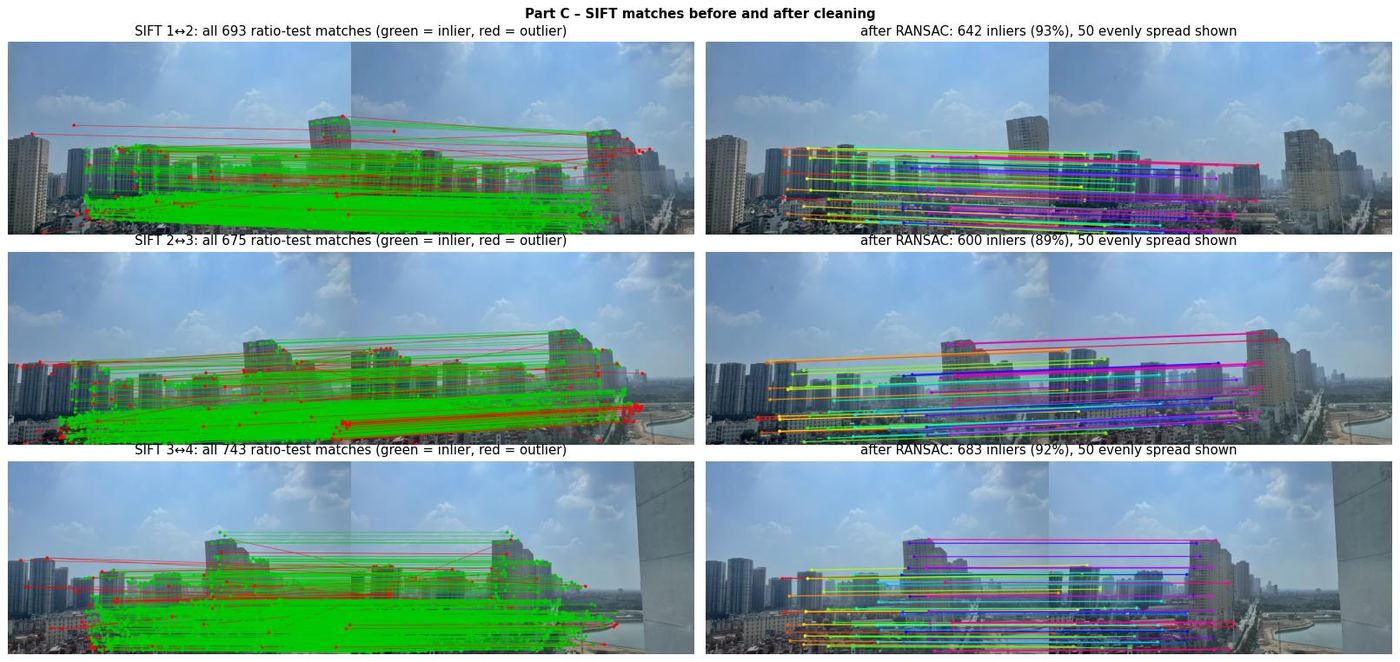

In [34]:
run_method("SIFT", "cylindrical")
match_figure(images, run_method("SIFT", "planar"), "SIFT", out_c)

### ORB method

,Detector,Projection,Pair,Keypoints,Ratio_matches,H_inliers,H_inlier_%,H_reproj_RMSE_px
0,ORB,cylindrical,1-2,5864/5681,734,611,83.243,1.441
1,ORB,cylindrical,2-3,5681/5846,854,780,91.335,1.290
2,ORB,cylindrical,3-4,5846/5817,1330,1192,89.624,1.459


,Detector,Projection,Pair,Keypoints,Ratio_matches,H_inliers,H_inlier_%,H_reproj_RMSE_px
0,ORB,planar,1-2,5864/5681,734,611,83.243,1.441
1,ORB,planar,2-3,5681/5846,854,780,91.335,1.290
2,ORB,planar,3-4,5846/5817,1330,1192,89.624,1.459


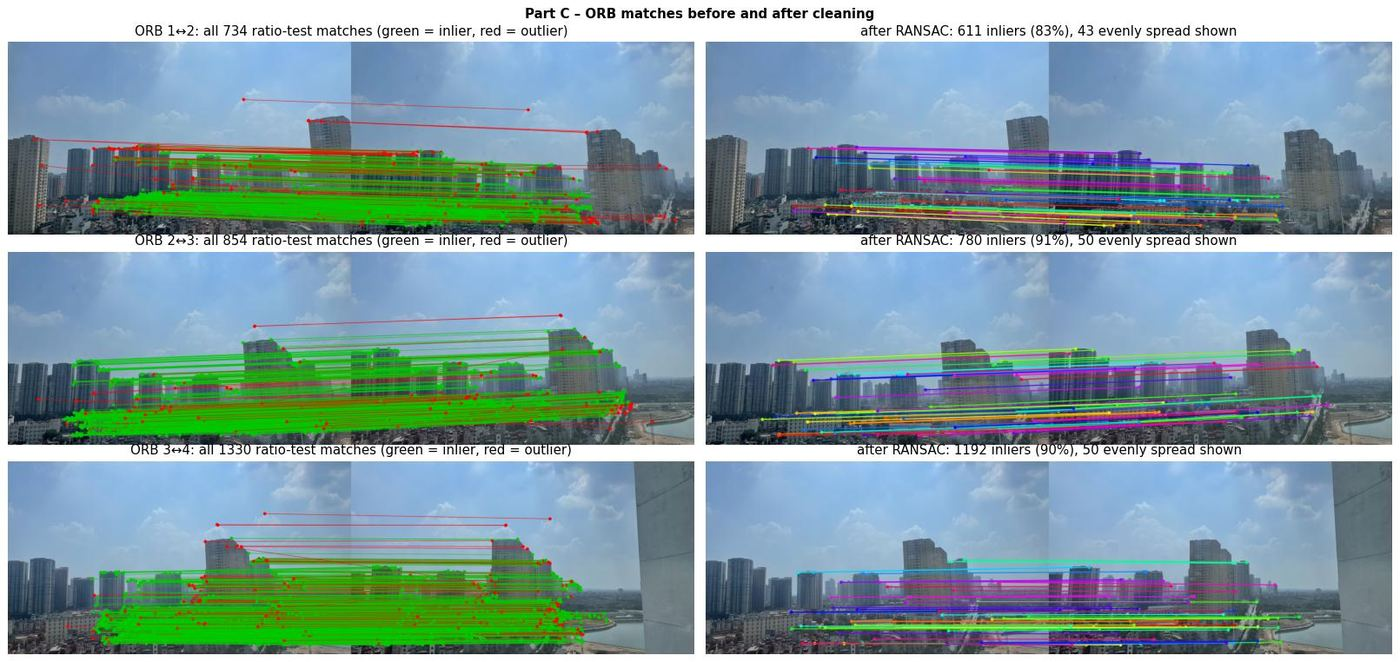

In [35]:
run_method("ORB", "cylindrical")
match_figure(images, run_method("ORB", "planar"), "ORB", out_c)

### AKAZE method

,Detector,Projection,Pair,Keypoints,Ratio_matches,H_inliers,H_inlier_%,H_reproj_RMSE_px
0,AKAZE,cylindrical,1-2,1804/1116,407,387,95.086,0.954
1,AKAZE,cylindrical,2-3,1116/1285,438,414,94.521,0.946
2,AKAZE,cylindrical,3-4,1285/1232,545,518,95.046,1.083


,Detector,Projection,Pair,Keypoints,Ratio_matches,H_inliers,H_inlier_%,H_reproj_RMSE_px
0,AKAZE,planar,1-2,1804/1116,407,387,95.086,0.954
1,AKAZE,planar,2-3,1116/1285,438,414,94.521,0.946
2,AKAZE,planar,3-4,1285/1232,545,518,95.046,1.083


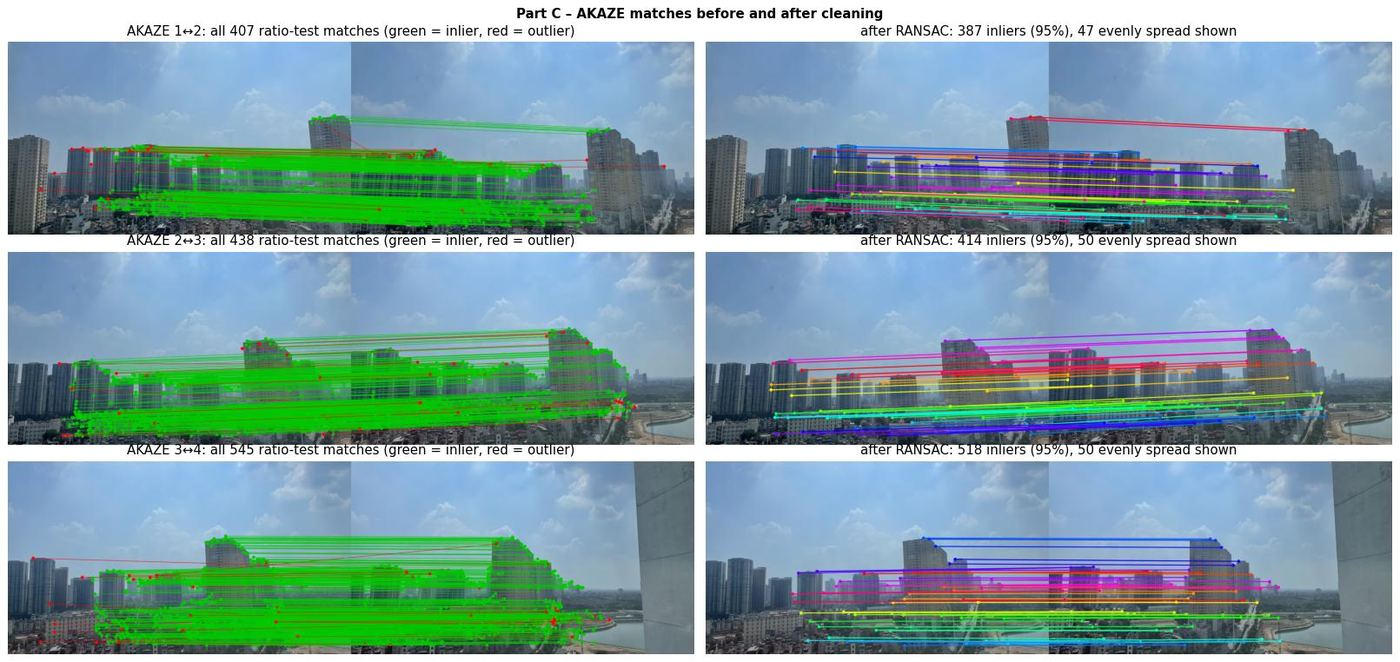

In [36]:
run_method("AKAZE", "cylindrical")
match_figure(images, run_method("AKAZE", "planar"), "AKAZE", out_c)

### Detector comparison and final panorama of each detector

,Detector,Keypoints_per_image,Initial_matches,Inliers,Inlier_%,Mean_RMSE_px,Total_stitching_time_ms
0,SIFT,2241.00,2111,1925,91.189,0.974,2361.822
1,ORB,5802.00,2918,2583,88.520,1.397,1431.637
2,AKAZE,1359.25,1390,1319,94.892,0.994,918.782


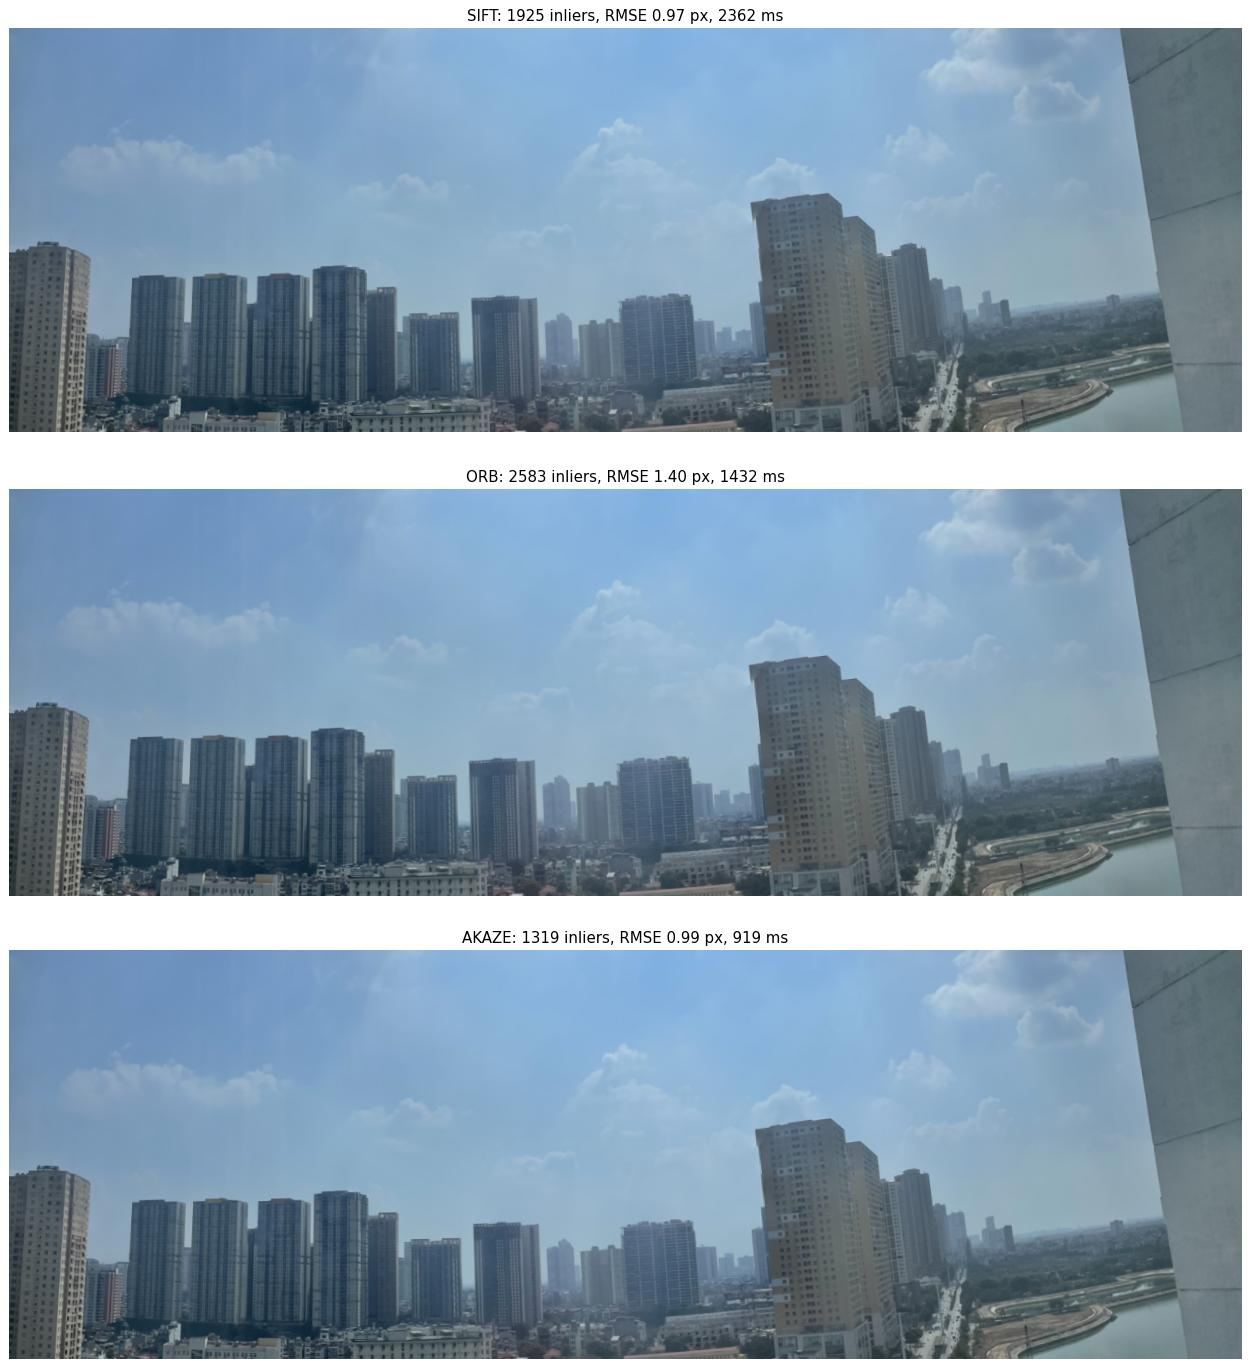

In [37]:
det_rows = []
for det in DETECTORS:
    r = results_c[(det, "cylindrical")]
    hp = r["hpairs"]
    kps = [hp[0]["n_kp"][0]] + [p["n_kp"][1] for p in hp]
    n_match = sum(len(p["good"]) for p in hp)
    n_inl = sum(int(p["inl"].sum()) for p in hp)
    det_rows.append({"Detector": det, "Keypoints_per_image": float(np.mean(kps)),
                     "Initial_matches": n_match, "Inliers": n_inl, "Inlier_%": 100.0 * n_inl / max(n_match, 1),
                     "Mean_RMSE_px": float(np.mean([s["H_reproj_RMSE_px"] for s in r["stats"]])),
                     "Total_stitching_time_ms": r["time_ms"]})
write_table(det_rows, os.path.join(out_c, "detector_comparison"))

pano0 = results_c[("SIFT", "cylindrical")]["final"]
fig, axes = plt.subplots(len(DETECTORS), 1, figsize=(14, len(DETECTORS) * (14 * pano0.shape[0] / pano0.shape[1] + 0.6)))
for ax, det, d in zip(axes, DETECTORS, det_rows):
    ax.imshow(bgr2rgb(results_c[(det, "cylindrical")]["final"]))
    ax.set_title(f"{det}: {d['Inliers']} inliers, RMSE {d['Mean_RMSE_px']:.2f} px, {d['Total_stitching_time_ms']:.0f} ms")
    ax.axis("off")
save_fig(fig, os.path.join(out_c, "C6_panorama_per_detector.png"), dpi=110)

### RANSAC threshold study (1 / 3 / 5 / 10 px)

,Detector,RANSAC_thr_px,Initial_matches,Inliers,Inlier_%,Mean_RMSE_px
0,SIFT,1.0,2111,1429,67.693,0.541
1,SIFT,3.0,2111,1925,91.189,0.974
2,SIFT,5.0,2111,1981,93.842,1.126
3,SIFT,10.0,2111,1995,94.505,1.227
4,ORB,1.0,2918,1229,42.118,0.634
5,ORB,3.0,2918,2583,88.520,1.397
6,ORB,5.0,2918,2804,96.093,1.565
7,ORB,10.0,2918,2844,97.464,1.690
8,AKAZE,1.0,1390,905,65.108,0.524
9,AKAZE,3.0,1390,1319,94.892,0.994


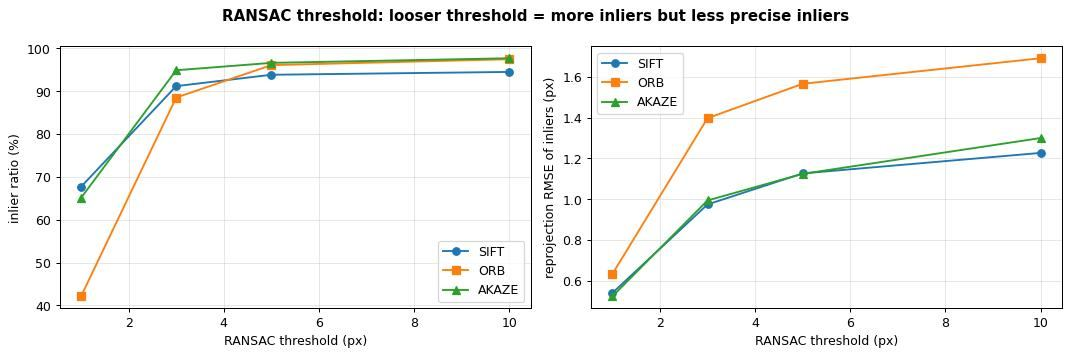

[{'Detector': 'SIFT',
  'RANSAC_thr_px': 1.0,
  'Initial_matches': 2111,
  'Inliers': 1429,
  'Inlier_%': 67.69303647560398,
  'Mean_RMSE_px': 0.54078941543897},
 {'Detector': 'SIFT',
  'RANSAC_thr_px': 3.0,
  'Initial_matches': 2111,
  'Inliers': 1925,
  'Inlier_%': 91.18900994789199,
  'Mean_RMSE_px': 0.9744826753934225},
 {'Detector': 'SIFT',
  'RANSAC_thr_px': 5.0,
  'Initial_matches': 2111,
  'Inliers': 1981,
  'Inlier_%': 93.84178114637612,
  'Mean_RMSE_px': 1.12645427385966},
 {'Detector': 'SIFT',
  'RANSAC_thr_px': 10.0,
  'Initial_matches': 2111,
  'Inliers': 1995,
  'Inlier_%': 94.50497394599716,
  'Mean_RMSE_px': 1.2268474102020264},
 {'Detector': 'ORB',
  'RANSAC_thr_px': 1.0,
  'Initial_matches': 2918,
  'Inliers': 1229,
  'Inlier_%': 42.11788896504455,
  'Mean_RMSE_px': 0.6335489153862},
 {'Detector': 'ORB',
  'RANSAC_thr_px': 3.0,
  'Initial_matches': 2918,
  'Inliers': 2583,
  'Inlier_%': 88.5195339273475,
  'Mean_RMSE_px': 1.3968668381373088},
 {'Detector': 'ORB',
  'R

In [38]:
def ransac_threshold_study(images, out):
    """Every detector × every consecutive pair × RANSAC thresholds 1/3/5/10 px."""
    rows = []
    for det in DETECTORS:
        feats = [detect(im, det) for im in images]
        for thr in RANSAC_THRESHOLDS:
            inl_tot, match_tot, rmses = 0, 0, []
            for i in range(len(images) - 1):
                (kq, dq), (kt, dt) = feats[i + 1], feats[i]
                good = match(dq, dt, det)
                src, dst = pair_points(kq, kt, good)
                H, mask = cv2.findHomography(src, dst, cv2.RANSAC, thr, maxIters=5000, confidence=0.999)
                inl = mask.ravel().astype(bool)
                inl_tot += int(inl.sum())
                match_tot += len(good)
                rmses.append(reprojection_rmse(H, src[inl], dst[inl]))
            rows.append({"Detector": det, "RANSAC_thr_px": thr, "Initial_matches": match_tot,
                         "Inliers": inl_tot, "Inlier_%": 100.0 * inl_tot / max(match_tot, 1),
                         "Mean_RMSE_px": float(np.mean(rmses))})
    write_table(rows, os.path.join(out, "ransac_threshold_study"))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for det, mk in zip(DETECTORS, ("o-", "s-", "^-")):
        sub = [r for r in rows if r["Detector"] == det]
        axes[0].plot(RANSAC_THRESHOLDS, [r["Inlier_%"] for r in sub], mk, label=det)
        axes[1].plot(RANSAC_THRESHOLDS, [r["Mean_RMSE_px"] for r in sub], mk, label=det)
    for ax, lab in zip(axes, ("inlier ratio (%)", "reprojection RMSE of inliers (px)")):
        ax.set_xlabel("RANSAC threshold (px)"); ax.set_ylabel(lab); ax.grid(alpha=0.3); ax.legend()
    fig.suptitle("RANSAC threshold: looser threshold = more inliers but less precise inliers", fontweight="bold")
    save_fig(fig, os.path.join(out, "C7_ransac_threshold_study.png"))
    return rows

ransac_threshold_study(images, out_c)

### Planar vs cylindrical projection (flat panorama)

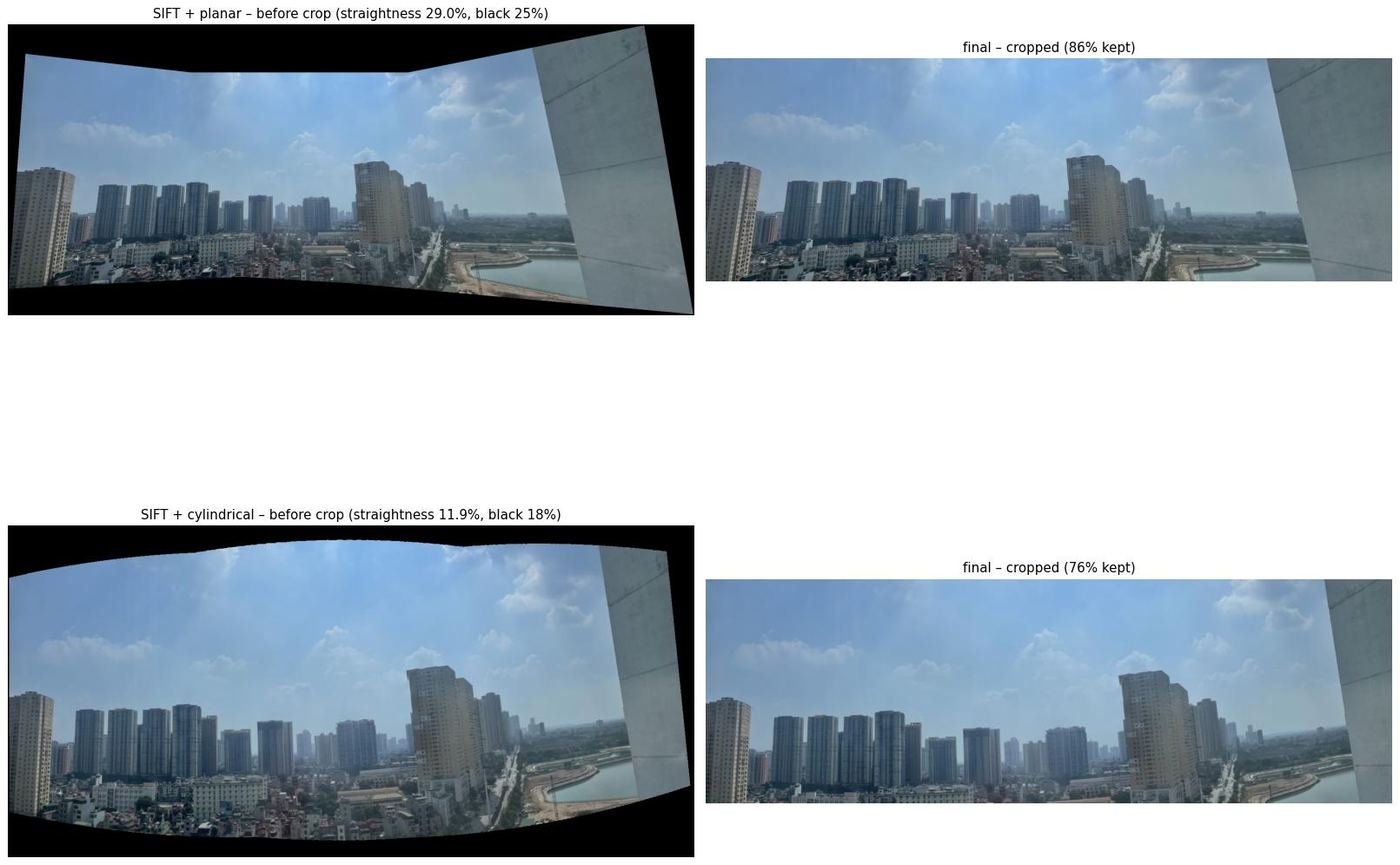

,Detector,Projection,Focal_px,Focal_from_H_px,Tilt_removed_deg,Mean_H_inliers,Mean_H_RMSE_px,Overlap_RMSE,Black_border_%_before_crop,Straightness_%,Area_kept_after_crop_%,Final_size,Total_time_ms
0,SIFT,cylindrical,866.7,722.0,2.41,641.667,0.974,10.861,18.327,11.914,76.188,1563x512,2361.822
1,SIFT,planar,-,-,0.00,641.667,0.974,10.003,24.970,29.044,85.654,2170x705,1351.254
2,ORB,cylindrical,866.7,878.2,2.29,861.000,1.397,10.923,18.466,11.646,76.567,1560x515,1431.637
3,ORB,planar,-,-,0.00,861.000,1.397,11.098,23.335,16.914,85.755,2225x705,1442.024
4,AKAZE,cylindrical,866.7,735.9,2.06,439.667,0.994,10.974,18.244,11.690,76.449,1554x515,918.782
5,AKAZE,planar,-,-,0.00,439.667,0.994,10.027,25.133,26.734,85.571,2193x706,1498.252


,Detector,Projection,Pair,Keypoints,Ratio_matches,H_inliers,H_inlier_%,H_reproj_RMSE_px
0,SIFT,cylindrical,1-2,2824/2001,693,642,92.641,1.027
1,SIFT,cylindrical,2-3,2001/2177,675,600,88.889,0.915
2,SIFT,cylindrical,3-4,2177/1962,743,683,91.925,0.982
3,SIFT,planar,1-2,2824/2001,693,642,92.641,1.027
4,SIFT,planar,2-3,2001/2177,675,600,88.889,0.915
5,SIFT,planar,3-4,2177/1962,743,683,91.925,0.982
6,ORB,cylindrical,1-2,5864/5681,734,611,83.243,1.441
7,ORB,cylindrical,2-3,5681/5846,854,780,91.335,1.290
8,ORB,cylindrical,3-4,5846/5817,1330,1192,89.624,1.459
9,ORB,planar,1-2,5864/5681,734,611,83.243,1.441


,Detector,Projection,Pair,Keypoints,Ratio_matches,H_inliers,H_inlier_%,H_reproj_RMSE_px
0,SIFT,cylindrical,1-2,2824/2001,693,642,92.641,1.027
1,SIFT,cylindrical,2-3,2001/2177,675,600,88.889,0.915
2,SIFT,cylindrical,3-4,2177/1962,743,683,91.925,0.982
3,SIFT,planar,1-2,2824/2001,693,642,92.641,1.027
4,SIFT,planar,2-3,2001/2177,675,600,88.889,0.915
5,SIFT,planar,3-4,2177/1962,743,683,91.925,0.982
6,ORB,cylindrical,1-2,5864/5681,734,611,83.243,1.441
7,ORB,cylindrical,2-3,5681/5846,854,780,91.335,1.290
8,ORB,cylindrical,3-4,5846/5817,1330,1192,89.624,1.459
9,ORB,planar,1-2,5864/5681,734,611,83.243,1.441


In [39]:
fig, axes = plt.subplots(2, 2, figsize=(18, 16))
for row, k in zip(axes, [("SIFT", "planar"), ("SIFT", "cylindrical")]):
    s = next(x for x in summary_c if (x["Detector"], x["Projection"]) == k)
    row[0].imshow(bgr2rgb(results_c[k]["raw"]))
    row[0].set_title(f"{k[0]} + {k[1]} – before crop (straightness {s['Straightness_%']:.1f}%, black {s['Black_border_%_before_crop']:.0f}%)")
    row[1].imshow(bgr2rgb(results_c[k]["final"]))
    row[1].set_title(f"final – cropped ({s['Area_kept_after_crop_%']:.0f}% kept)")
    for ax in row:
        ax.axis("off")
save_fig(fig, os.path.join(out_c, "C2_projection_comparison.png"), dpi=100)
write_table(summary_c, os.path.join(out_c, "panorama_comparison"))
write_table(rows_c, os.path.join(out_c, "pairwise_matching_metrics"))

### Blending: overwrite vs feather vs multi-band

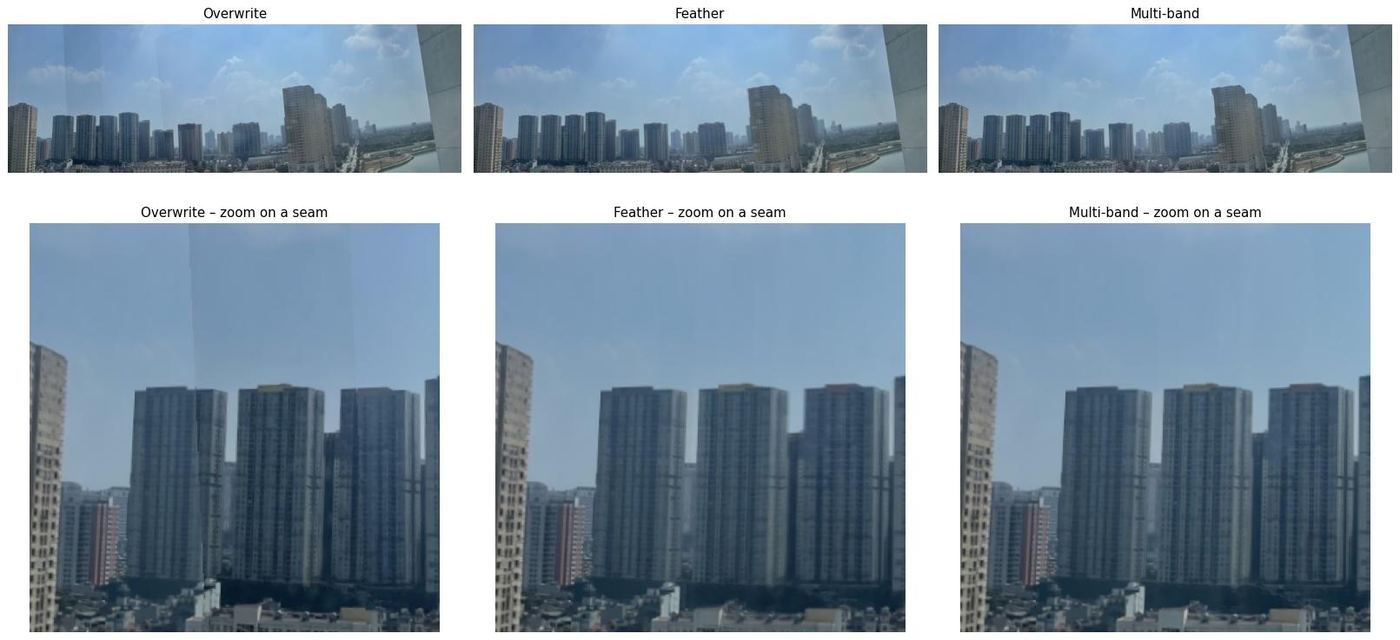

In [40]:
r = results_c[("SIFT", "cylindrical")]
panos = {name: fn(r["warped"], r["masks"]) for name, fn in BLENDERS.items()}
valid = np.max(np.stack(r["masks"]), axis=0) > 0
y0, y1, x0, x1 = largest_valid_rectangle(valid)
diff = cv2.absdiff(panos["Overwrite"], panos["Multi-band"]).astype(np.float32).mean(axis=2)
both = np.sum([m > 0 for m in r["masks"]], axis=0) >= 2
cy, cx = np.unravel_index(np.argmax(cv2.boxFilter(np.where(both, diff, 0), -1, (61, 61))), diff.shape)
half = 160
fig, axes = plt.subplots(2, 3, figsize=(18, 9), gridspec_kw=dict(height_ratios=[1, 1.4]))
for k, (name, p) in enumerate(panos.items()):
    cv2.imwrite(os.path.join(out_c, f"C4_blend_{name.lower().replace('-', '')}.jpg"), p[y0:y1, x0:x1])
    axes[0, k].imshow(bgr2rgb(p[y0:y1, x0:x1])); axes[0, k].set_title(name)
    axes[1, k].imshow(bgr2rgb(p[max(cy - half, 0):cy + half, max(cx - half, 0):cx + half]))
    axes[1, k].set_title(f"{name} – zoom on a seam")
for ax in axes.ravel():
    ax.axis("off")
save_fig(fig, os.path.join(out_c, "C4_blending_comparison.png"), dpi=100)

### Homography estimator: least squares vs RANSAC vs LMedS

In [41]:
def homography_estimator_study(images, out):
    """Same SIFT matches of pair 1-2: least squares vs RANSAC (3 thresholds) vs LMedS,
    with and without 20 % extra synthetic outliers."""
    (kq, dq), (kt, dt) = detect(images[1], "SIFT"), detect(images[0], "SIFT")
    good = match(dq, dt, "SIFT")
    src, dst = pair_points(kq, kt, good)
    H_ref, m_ref = cv2.findHomography(src, dst, cv2.RANSAC, 1.0)
    ref_inl = m_ref.ravel().astype(bool)
    rng = np.random.default_rng(0)
    h, w = images[0].shape[:2]
    n_out = len(src) // 5
    src_c = np.vstack([src, rng.uniform([0, 0], [w, h], (n_out, 2)).astype(np.float32)])
    dst_c = np.vstack([dst, rng.uniform([0, 0], [w, h], (n_out, 2)).astype(np.float32)])
    rows = []
    for name, meth, thr in [("Least squares (all)", 0, 0), ("RANSAC thr=1px", cv2.RANSAC, 1.0),
                            ("RANSAC thr=3px", cv2.RANSAC, 3.0), ("RANSAC thr=10px", cv2.RANSAC, 10.0),
                            ("LMedS", cv2.LMEDS, 0)]:
        for label, s, d in (("ratio-test matches", src, dst), ("+20% random outliers", src_c, dst_c)):
            t = {}
            with timer(t, "ms"):
                H, mask = cv2.findHomography(s, d, meth, thr)
            inl = mask.ravel().astype(bool) if (mask is not None and meth) else np.ones(len(s), bool)
            e = reprojection_errors(H, src[ref_inl], dst[ref_inl])
            rows.append({"Estimator": name, "Data": label, "Inliers": int(inl.sum()), "Total": len(s),
                         "RMSE_on_true_inliers_px": float(np.sqrt(np.mean(e ** 2))), "Time_ms": t["ms"]})
    write_table(rows, os.path.join(out, "homography_estimator_comparison"))

homography_estimator_study(images, out_c)
for i, p in enumerate(results_c[("SIFT", "planar")]["hpairs"]):
    print(f"H_{i + 2}->{i + 1} =\n", np.array2string(p["T"], precision=5, suppress_small=True))

,Estimator,Data,Inliers,Total,RMSE_on_true_inliers_px,Time_ms
0,Least squares (all),ratio-test matches,693,693,18.617,0.808
1,Least squares (all),+20% random outliers,831,831,195.318,0.824
2,RANSAC thr=1px,ratio-test matches,463,693,0.464,1.576
3,RANSAC thr=1px,+20% random outliers,469,831,0.475,2.483
4,RANSAC thr=3px,ratio-test matches,642,693,0.849,0.648
5,RANSAC thr=3px,+20% random outliers,623,831,0.627,0.989
6,RANSAC thr=10px,ratio-test matches,654,693,0.844,0.715
7,RANSAC thr=10px,+20% random outliers,654,831,0.847,0.782
8,LMedS,ratio-test matches,608,693,0.500,2.175
9,LMedS,+20% random outliers,616,831,0.597,2.310


H_2->1 =
 [[  0.74564   0.05411 238.07273]
 [ -0.10162   0.90326  26.39093]
 [ -0.00022   0.00002   1.     ]]
H_3->2 =
 [[  0.79345  -0.02456 180.50712]
 [ -0.06336   0.88334  74.48503]
 [ -0.00016  -0.00005   1.     ]]
H_4->3 =
 [[  0.71932   0.04804 242.21658]
 [ -0.12607   0.87514  66.99905]
 [ -0.00023  -0.00001   1.     ]]


## Final panorama

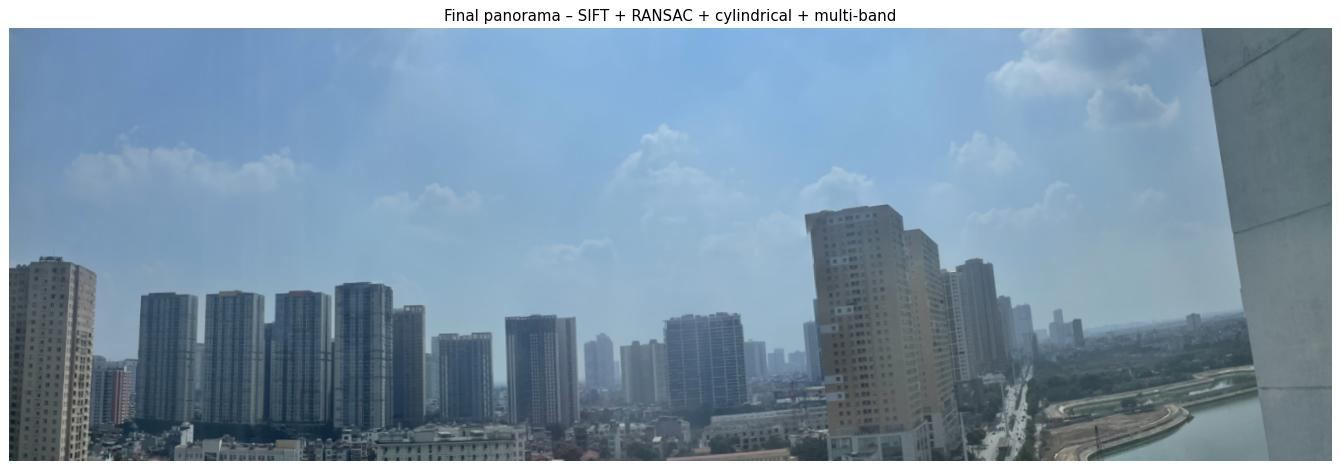

In [42]:
final = results_c[("SIFT", "cylindrical")]["final"]
cv2.imwrite(os.path.join(out_c, "C5_FINAL_PANORAMA.jpg"), final)
fig, ax = plt.subplots(figsize=(15, 15 * final.shape[0] / final.shape[1] + 0.6))
ax.imshow(bgr2rgb(final)); ax.set_title("Final panorama – SIFT + RANSAC + cylindrical + multi-band"); ax.axis("off")
save_fig(fig, os.path.join(out_c, "C5_final_panorama_figure.png"), dpi=100)

### Part C – Comparative analysis
* **SIFT vs ORB vs AKAZE**: ORB detects the most keypoints and inliers (FAST corners on buildings and windows) but its
  binary matches are the least precise (RMSE ≈ 1.4 px vs ≈ 1.0 px). SIFT gives many precise inliers but is the
  slowest; AKAZE has the highest inlier ratio (≈ 95 %), SIFT-like precision and the shortest total time.
* **RANSAC threshold**: 1 px keeps only 42–68 % of the matches (very precise, ≈ 0.5 px), 3 px keeps ≈ 90 %;
  5–10 px add a few more inliers but also less accurate ones (higher RMSE).
* **RANSAC is essential**: plain least squares on all matches gives errors of 19 px (195 px with 20 % extra outliers).
* **Planar vs cylindrical**: planar warping stretches the outer photo (the wall on the right) and leaves a bow-tie
  outline (straightness 29 %); cylindrical projection with the EXIF focal length keeps proportions and a flatter
  outline (12 %). The focal length self-estimated from the homographies is too small (722 px vs 867 px from EXIF)
  because the rotations between shots are small, which is why EXIF is used.
* **Blending**: overwrite shows hard exposure seams, feathering hides them but slightly ghosts details, multi-band
  blending gives seamless transitions while keeping details sharp.

## Conclusion
* **A**: the median filter is the right tool for impulse noise, a Gaussian for sensor noise; larger kernels trade
  edges for noise reduction; Laplacian sharpening only after denoising and with a moderate α (halos otherwise).
* **B**: SGBM's global smoothness gives denser and more reliable disparity than local BM; numDisparities must cover
  the true range without being too large; robust estimators are mandatory for the fundamental matrix.
* **C**: SIFT/AKAZE + RANSAC homography + cylindrical projection + multi-band blending produces a flat, seamless
  panorama of my four photos.